Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['food' 'price' 'service']
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters: {'clf__alpha': 0.5, 'vect__max_df': 0.8, 'vect__min_df': 1}
Model cross-validation scores: [0.64304933 0.62926391 0.66696589 0.65170557 0.66517056]
Mean cross-validation score: 0.651
Test Accuracy: 0.664
Classification Report:
              precision    recall  f1-score   support

        food       0.94      0.68      0.79       556
       price       0.15      0.67      0.24        21
     service       0.14      0.40      0.21        42

    accuracy                           0.66       619
   macro avg       0.41      0.58      0.41       619
weighted avg       0.86      0.66      0.73       619



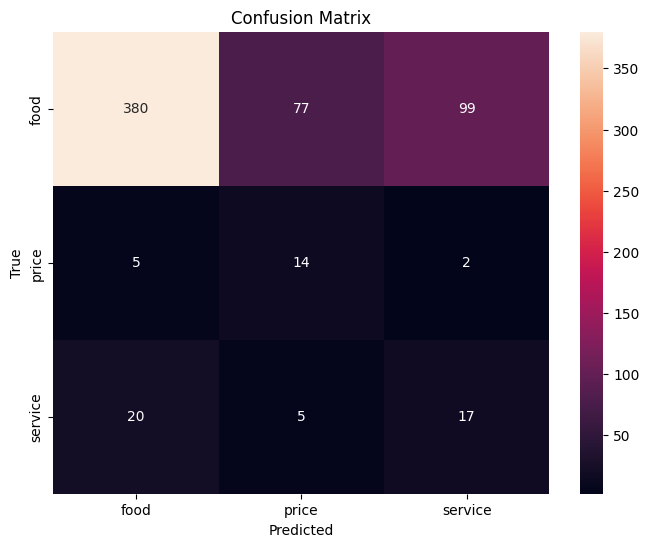

Predicted label: food


In [ ]:
!pip install emoji
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

X = data['Comment']
y = data['Aspect']

# Split data into training and testing sets with stratification to ensure balanced splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-fold cross-validation (e.g., 5-fold)
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Hyperparameter grid for GridSearchCV
param_grid = {
    'vect__max_df': [0.8, 0.9, 1.0],  # Maximum document frequency for TfidfVectorizer
    'vect__min_df': [1, 2],  # Minimum document frequency for TfidfVectorizer
    'clf__alpha': [0.5, 1.0, 1.5]  # Smoothing parameter for MultinomialNB
}

# Function to create the model pipeline with optional SMOTE
def create_smote_pipeline():
    return ImbPipeline([  # For imbalanced data, you can also consider using SMOTE
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('smote', SMOTE(random_state=42)),  # Handle class imbalance with SMOTE
        ('clf', MultinomialNB())      # Naive Bayes classifier
    ])

# Set up the pipeline
model_pipeline = create_smote_pipeline()

# Perform GridSearchCV for classification model
grid_search = GridSearchCV(model_pipeline, param_grid, cv=kf, n_jobs=-1, verbose=1, scoring='accuracy')
grid_search.fit(X_train, y_train_int)

# Get the best model and its parameters
best_model = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)

# Perform K-fold Cross-validation scores for the model
cross_val_scores = cross_val_score(best_model, X_train, y_train_int, cv=kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model on the test set
predictions = best_model.predict(X_test)
accuracy = accuracy_score(y_test_int, predictions)
print(f'Test Accuracy: {accuracy:.3f}')
print('Classification Report:')
print(classification_report(y_test_int, predictions, target_names=label_encoder.classes_))

# Plot confusion matrix using a heatmap
cm = confusion_matrix(y_test_int, predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions using the best model
def make_prediction(comment):
    predicted_label = best_model.predict([comment])
    label = label_encoder.inverse_transform(predicted_label)
    print(f'Predicted label: {label[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['food' 'price' 'service']
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters: {'clf__alpha': 1.0, 'vect__max_df': 0.8, 'vect__min_df': 1}
Model cross-validation scores: [0.6367713  0.65709156 0.68940754 0.65170557 0.67235189]
Mean cross-validation score: 0.661
Test Accuracy: 0.659
Classification Report:
              precision    recall  f1-score   support

        food       0.94      0.67      0.79       556
       price       0.15      0.71      0.24        21
     service       0.15      0.43      0.23        42

    accuracy                           0.66       619
   macro avg       0.41      0.61      0.42       619
weighted avg       0.86      0.66      0.73       619



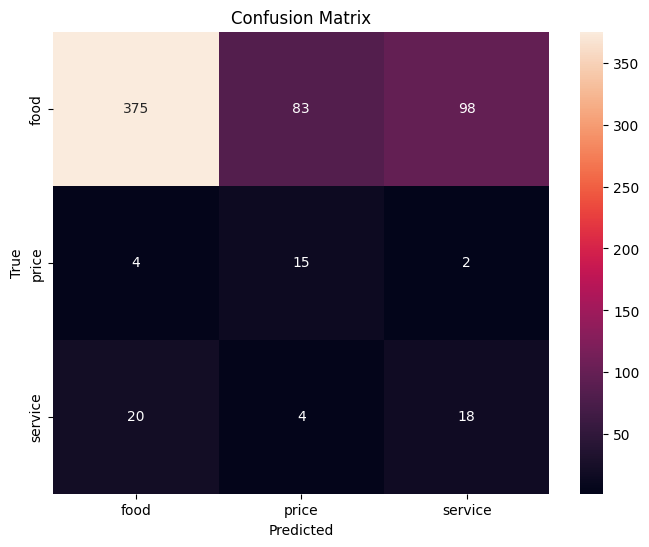

Predicted label: food


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

X = data['Comment']
y = data['Aspect']

# Split data into training and testing sets with stratification to ensure balanced splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-fold cross-validation (e.g., 5-fold)
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Hyperparameter grid for GridSearchCV
param_grid = {
    'vect__max_df': [0.8, 0.9, 1.0],  # Maximum document frequency for TfidfVectorizer
    'vect__min_df': [1, 2],  # Minimum document frequency for TfidfVectorizer
    'clf__alpha': [0.5, 1.0, 1.5]  # Smoothing parameter for MultinomialNB
}

# Function to create the model pipeline with optional SMOTE
def create_smote_pipeline():
    return ImbPipeline([  # For imbalanced data, you can also consider using SMOTE
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('smote', SMOTE(random_state=42)),  # Handle class imbalance with SMOTE
        ('clf', MultinomialNB())      # Naive Bayes classifier
    ])

# Set up the pipeline
model_pipeline = create_smote_pipeline()

# Perform GridSearchCV for classification model
grid_search = GridSearchCV(model_pipeline, param_grid, cv=kf, n_jobs=-1, verbose=1, scoring='accuracy')
grid_search.fit(X_train, y_train_int)

# Get the best model and its parameters
best_model = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)

# Perform K-fold Cross-validation scores for the model
cross_val_scores = cross_val_score(best_model, X_train, y_train_int, cv=kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model on the test set
predictions = best_model.predict(X_test)
accuracy = accuracy_score(y_test_int, predictions)
print(f'Test Accuracy: {accuracy:.3f}')
print('Classification Report:')
print(classification_report(y_test_int, predictions, target_names=label_encoder.classes_))

# Plot confusion matrix using a heatmap
cm = confusion_matrix(y_test_int, predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions using the best model
def make_prediction(comment):
    predicted_label = best_model.predict([comment])
    label = label_encoder.inverse_transform(predicted_label)
    print(f'Predicted label: {label[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['conflict' 'negative' 'neutral' 'positive']
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters: {'clf__alpha': 0.5, 'vect__max_df': 0.8, 'vect__min_df': 1}
Model cross-validation scores: [0.62242152 0.5978456  0.64003591 0.62387792 0.60412926]
Mean cross-validation score: 0.618
Test Accuracy: 0.632
Classification Report:
              precision    recall  f1-score   support

    conflict       0.14      0.49      0.22        39
    negative       0.88      0.67      0.76       380
     neutral       0.27      0.56      0.36        27
    positive       0.75      0.59      0.66       173

    accuracy                           0.63       619
   macro avg       0.51      0.58      0.50       619
weighted avg       0.77      0.63      0.68       619



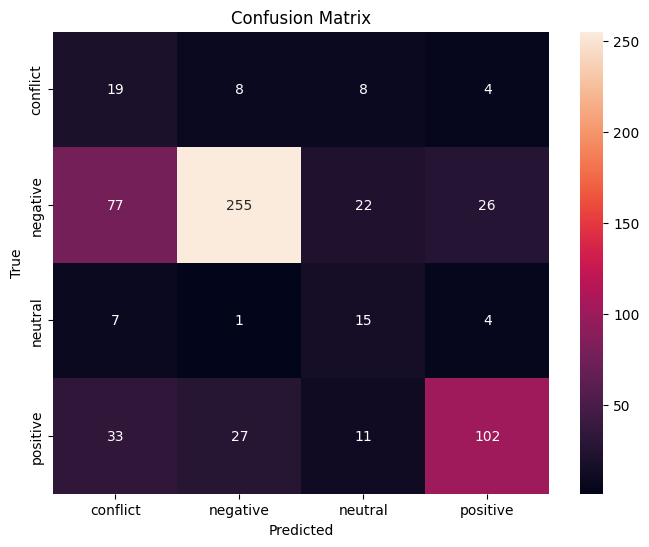

Predicted label: conflict


In [ ]:
!pip install emoji
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

X = data['Comment']
y = data['Sentiment']

# Split data into training and testing sets with stratification to ensure balanced splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-fold cross-validation (e.g., 5-fold)
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Hyperparameter grid for GridSearchCV
param_grid = {
    'vect__max_df': [0.8, 0.9, 1.0],  # Maximum document frequency for TfidfVectorizer
    'vect__min_df': [1, 2],  # Minimum document frequency for TfidfVectorizer
    'clf__alpha': [0.5, 1.0, 1.5]  # Smoothing parameter for MultinomialNB
}

# Function to create the model pipeline with optional SMOTE
def create_smote_pipeline():
    return ImbPipeline([  # For imbalanced data, you can also consider using SMOTE
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('smote', SMOTE(random_state=42)),  # Handle class imbalance with SMOTE
        ('clf', MultinomialNB())      # Naive Bayes classifier
    ])

# Set up the pipeline
model_pipeline = create_smote_pipeline()

# Perform GridSearchCV for classification model
grid_search = GridSearchCV(model_pipeline, param_grid, cv=kf, n_jobs=-1, verbose=1, scoring='accuracy')
grid_search.fit(X_train, y_train_int)

# Get the best model and its parameters
best_model = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)

# Perform K-fold Cross-validation scores for the model
cross_val_scores = cross_val_score(best_model, X_train, y_train_int, cv=kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model on the test set
predictions = best_model.predict(X_test)
accuracy = accuracy_score(y_test_int, predictions)
print(f'Test Accuracy: {accuracy:.3f}')
print('Classification Report:')
print(classification_report(y_test_int, predictions, target_names=label_encoder.classes_))

# Plot confusion matrix using a heatmap
cm = confusion_matrix(y_test_int, predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions using the best model
def make_prediction(comment):
    predicted_label = best_model.predict([comment])
    label = label_encoder.inverse_transform(predicted_label)
    print(f'Predicted label: {label[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['conflict' 'negative' 'neutral' 'positive']
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters: {'clf__alpha': 1.5, 'vect__max_df': 0.8, 'vect__min_df': 1}
Model cross-validation scores: [0.59730942 0.57271095 0.62208259 0.5978456  0.59425494]
Mean cross-validation score: 0.597
Test Accuracy: 0.628
Classification Report:
              precision    recall  f1-score   support

    conflict       0.15      0.51      0.23        39
    negative       0.87      0.66      0.75       380
     neutral       0.29      0.59      0.39        27
    positive       0.73      0.58      0.65       173

    accuracy                           0.63       619
   macro avg       0.51      0.59      0.50       619
weighted avg       0.76      0.63      0.67       619



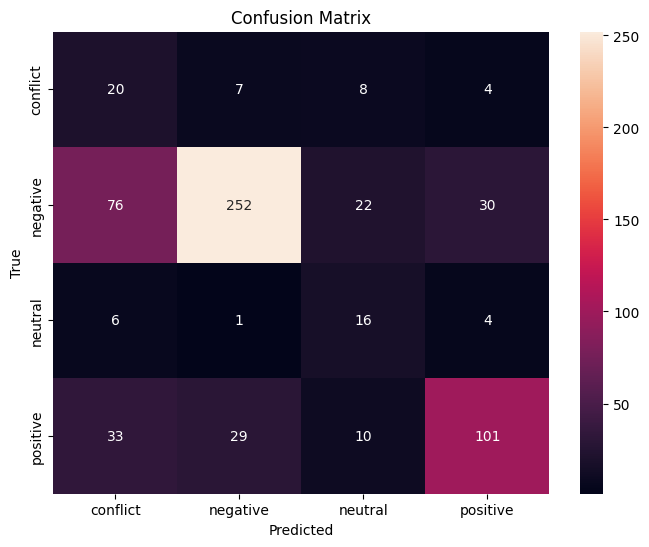

Predicted label: conflict


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

X = data['Comment']
y = data['Sentiment']

# Split data into training and testing sets with stratification to ensure balanced splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-fold cross-validation (e.g., 5-fold)
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Hyperparameter grid for GridSearchCV
param_grid = {
    'vect__max_df': [0.8, 0.9, 1.0],  # Maximum document frequency for TfidfVectorizer
    'vect__min_df': [1, 2],  # Minimum document frequency for TfidfVectorizer
    'clf__alpha': [0.5, 1.0, 1.5]  # Smoothing parameter for MultinomialNB
}

# Function to create the model pipeline with optional SMOTE
def create_smote_pipeline():
    return ImbPipeline([  # For imbalanced data, you can also consider using SMOTE
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('smote', SMOTE(random_state=42)),  # Handle class imbalance with SMOTE
        ('clf', MultinomialNB())      # Naive Bayes classifier
    ])

# Set up the pipeline
model_pipeline = create_smote_pipeline()

# Perform GridSearchCV for classification model
grid_search = GridSearchCV(model_pipeline, param_grid, cv=kf, n_jobs=-1, verbose=1, scoring='accuracy')
grid_search.fit(X_train, y_train_int)

# Get the best model and its parameters
best_model = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)

# Perform K-fold Cross-validation scores for the model
cross_val_scores = cross_val_score(best_model, X_train, y_train_int, cv=kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model on the test set
predictions = best_model.predict(X_test)
accuracy = accuracy_score(y_test_int, predictions)
print(f'Test Accuracy: {accuracy:.3f}')
print('Classification Report:')
print(classification_report(y_test_int, predictions, target_names=label_encoder.classes_))

# Plot confusion matrix using a heatmap
cm = confusion_matrix(y_test_int, predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions using the best model
def make_prediction(comment):
    predicted_label = best_model.predict([comment])
    label = label_encoder.inverse_transform(predicted_label)
    print(f'Predicted label: {label[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['food' 'price' 'service']
Best parameters: {'clf__C': 20, 'clf__gamma': 'scale'}
Model cross-validation scores: [0.68609865 0.7037702  0.69479354 0.68940754 0.7010772 ]
Mean cross-validation score: 0.695
Test Accuracy : 0.669
Classification Report :
              precision    recall  f1-score   support

        food       0.92      0.70      0.79       556
       price       0.13      0.52      0.21        21
     service       0.14      0.38      0.21        42

    accuracy                           0.67       619
   macro avg       0.40      0.53      0.40       619
weighted avg       0.84      0.67      0.73       619



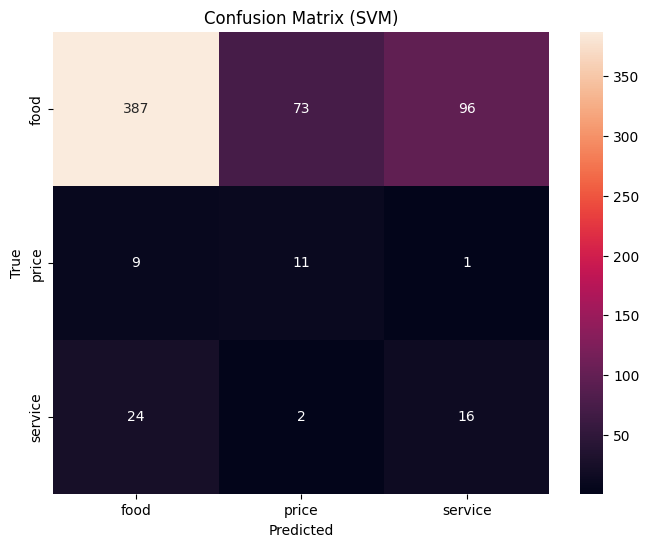

Predicted label: food


In [ ]:
!pip install emoji seaborn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

# Define X and y for classification
X = data['Comment']

y = data['Aspect']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create an SVM pipeline
def create_svm_pipeline():
    return Pipeline([  # Use class weights to handle imbalance
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', SVC(kernel='linear', class_weight='balanced', random_state=42))  # SVM classifier with class_weight='balanced'
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__C': [0.1 , 1, 10, 20 ],  # Regularization parameter
    'clf__gamma': ['scale']  # Kernel coefficient
}

# Create and tune the model with Grid Search
model_svm = create_svm_pipeline()
grid_search = GridSearchCV(model_svm, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_svm = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_svm, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_svm = best_model_svm.predict(X_test)
accuracy_svm = accuracy_score(y_test_int, predictions_svm)
print(f'Test Accuracy : {accuracy_svm:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_svm, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_svm = confusion_matrix(y_test_int, predictions_svm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (SVM)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with SVM
def make_prediction_svm(comment):
    predicted_label_svm = best_model_svm.predict([comment])
    label_svm = label_encoder.inverse_transform(predicted_label_svm)
    print(f'Predicted label: {label_svm[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_svm(new_comment)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['food' 'price' 'service']
Best parameters: {'clf__C': 20, 'clf__gamma': 'scale'}
Model cross-validation scores: [0.68340807 0.6929982  0.68761221 0.69120287 0.68850987]
Mean cross-validation score: 0.689
Test Accuracy : 0.677
Classification Report :
              precision    recall  f1-score   support

        food       0.93      0.70      0.80       556
       price       0.14      0.62      0.23        21
     service       0.15      0.38      0.21        42

    accuracy                           0.68       619
   macro avg       0.41      0.57      0.42       619
weighted avg       0.85      0.68      0.74       619



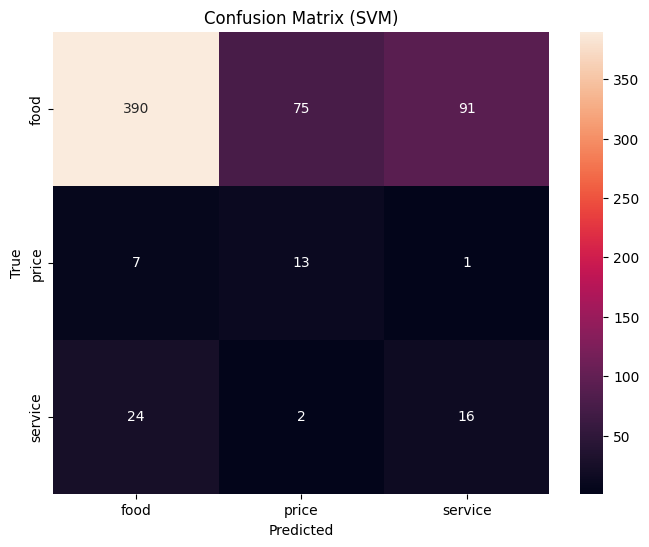

Predicted label: food


In [ ]:
!pip install seaborn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)


# Define X and y for classification
X = data['Comment']

y = data['Aspect']
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create an SVM pipeline
def create_svm_pipeline():
    return Pipeline([  # Use class weights to handle imbalance
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', SVC(kernel='linear', class_weight='balanced', random_state=42))  # SVM classifier with class_weight='balanced'
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__C': [0.1 , 1, 10 ,20 ],  # Regularization parameter
    'clf__gamma': ['scale']  # Kernel coefficient
}

# Create and tune the model with Grid Search
model_svm = create_svm_pipeline()
grid_search = GridSearchCV(model_svm, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_svm = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_svm, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_svm = best_model_svm.predict(X_test)
accuracy_svm = accuracy_score(y_test_int, predictions_svm)
print(f'Test Accuracy : {accuracy_svm:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_svm, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_svm = confusion_matrix(y_test_int, predictions_svm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (SVM)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with SVM
def make_prediction_svm(comment):
    predicted_label_svm = best_model_svm.predict([comment])
    label_svm = label_encoder.inverse_transform(predicted_label_svm)
    print(f'Predicted label: {label_svm[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_svm(new_comment)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['conflict' 'negative' 'neutral' 'positive']
Best parameters: {'clf__C': 0.1, 'clf__gamma': 'scale'}
Model cross-validation scores: [0.69327354 0.64901257 0.70197487 0.66157989 0.67594255]
Mean cross-validation score: 0.676
Test Accuracy : 0.664
Classification Report :
              precision    recall  f1-score   support

    conflict       0.18      0.38      0.25        39
    negative       0.85      0.69      0.76       380
     neutral       0.33      0.59      0.43        27
    positive       0.65      0.69      0.67       173

    accuracy                           0.66       619
   macro avg       0.50      0.59      0.53       619
weighted avg       0.73      0.66      0.69       619



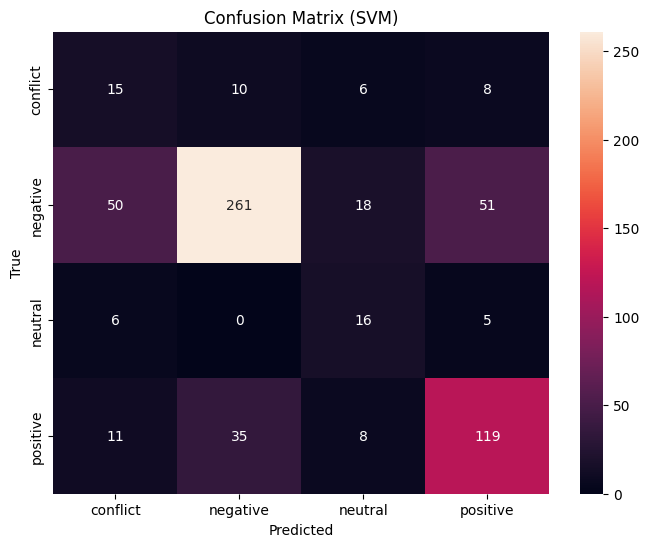

Predicted label: positive


In [ ]:
!pip install emoji seaborn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

# Define X and y for classification
X = data['Comment']

y = data['Sentiment']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create an SVM pipeline
def create_svm_pipeline():
    return Pipeline([  # Use class weights to handle imbalance
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', SVC(kernel='linear', class_weight='balanced', random_state=42))  # SVM classifier with class_weight='balanced'
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__C': [0.1, 1, 100],  # Regularization parameter
    'clf__gamma': ['scale']  # Kernel coefficient
}

# Create and tune the model with Grid Search
model_svm = create_svm_pipeline()
grid_search = GridSearchCV(model_svm, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_svm = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_svm, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_svm = best_model_svm.predict(X_test)
accuracy_svm = accuracy_score(y_test_int, predictions_svm)
print(f'Test Accuracy : {accuracy_svm:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_svm, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_svm = confusion_matrix(y_test_int, predictions_svm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (SVM)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with SVM
def make_prediction_svm(comment):
    predicted_label_svm = best_model_svm.predict([comment])
    label_svm = label_encoder.inverse_transform(predicted_label_svm)
    print(f'Predicted label: {label_svm[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_svm(new_comment)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['conflict' 'negative' 'neutral' 'positive']
Best parameters: {'clf__C': 0.1, 'clf__gamma': 'scale'}
Model cross-validation scores: [0.68161435 0.63375224 0.69389587 0.64721724 0.67235189]
Mean cross-validation score: 0.666
Test Accuracy : 0.658
Classification Report :
              precision    recall  f1-score   support

    conflict       0.21      0.38      0.27        39
    negative       0.85      0.67      0.75       380
     neutral       0.32      0.59      0.42        27
    positive       0.62      0.70      0.66       173

    accuracy                           0.66       619
   macro avg       0.50      0.59      0.52       619
weighted avg       0.72      0.66      0.68       619



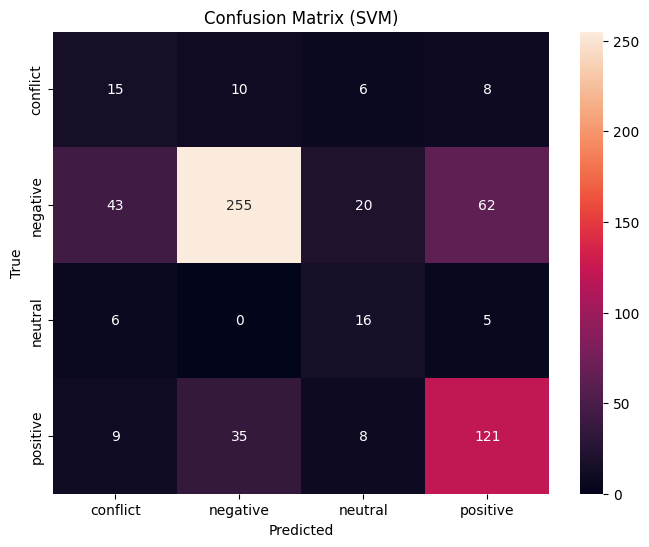

Predicted label: positive


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define X and y for classification
X = data['Comment']

y = data['Sentiment']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create an SVM pipeline
def create_svm_pipeline():
    return Pipeline([  # Use class weights to handle imbalance
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', SVC(kernel='linear', class_weight='balanced', random_state=42))  # SVM classifier with class_weight='balanced'
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__C': [0.1, 1, 100],  # Regularization parameter
    'clf__gamma': ['scale']  # Kernel coefficient
}

# Create and tune the model with Grid Search
model_svm = create_svm_pipeline()
grid_search = GridSearchCV(model_svm, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_svm = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_svm, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_svm = best_model_svm.predict(X_test)
accuracy_svm = accuracy_score(y_test_int, predictions_svm)
print(f'Test Accuracy : {accuracy_svm:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_svm, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_svm = confusion_matrix(y_test_int, predictions_svm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (SVM)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with SVM
def make_prediction_svm(comment):
    predicted_label_svm = best_model_svm.predict([comment])
    label_svm = label_encoder.inverse_transform(predicted_label_svm)
    print(f'Predicted label: {label_svm[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_svm(new_comment)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['food' 'price' 'service']
Best parameters: {'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': None, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 2}
Model cross-validation scores: [0.73721973 0.76750449 0.75942549 0.76750449 0.75942549]
Mean cross-validation score: 0.758
Test Accuracy : 0.763
Classification Report :
              precision    recall  f1-score   support

        food       0.91      0.83      0.87       556
       price       0.08      0.19      0.11        21
     service       0.12      0.17      0.14        42

    accuracy                           0.76       619
   macro avg       0.37      0.40      0.37       619
weighted avg       0.83      0.76      0.79       619



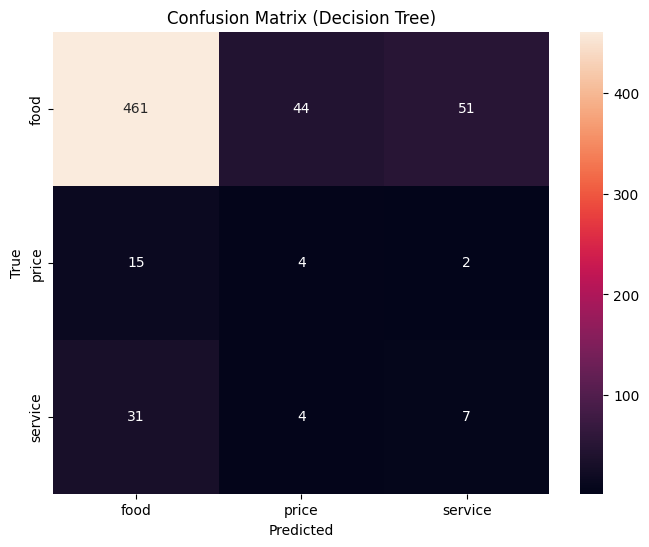

Predicted label: food


In [ ]:
!pip install emoji seaborn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

# Define X and y for classification
X = data['Comment']
y = data['Aspect']
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create a Decision Tree pipeline
def create_dt_pipeline():
    return ImbPipeline([
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', DecisionTreeClassifier(random_state=42))  # Decision Tree classifier
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__max_depth': [10, 20, 30, None],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4],
    'clf__class_weight': ['balanced'],
    'clf__criterion': ['entropy']
}

# Create and tune the model with Grid Search
model_dt = create_dt_pipeline()
grid_search = GridSearchCV(model_dt, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_dt = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_dt, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_dt = best_model_dt.predict(X_test)
accuracy_dt = accuracy_score(y_test_int, predictions_dt)
print(f'Test Accuracy : {accuracy_dt:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_dt, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_dt = confusion_matrix(y_test_int, predictions_dt)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (Decision Tree)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with Decision Tree
def make_prediction_dt(comment):
    predicted_label_dt = best_model_dt.predict([comment])
    label_dt = label_encoder.inverse_transform(predicted_label_dt)
    print(f'Predicted label: {label_dt[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_dt(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['food' 'price' 'service']
Best parameters: {'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': None, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 2}
Model cross-validation scores: [0.74618834 0.76660682 0.77378815 0.77019749 0.76211849]
Mean cross-validation score: 0.764
Test Accuracy : 0.763
Classification Report :
              precision    recall  f1-score   support

        food       0.91      0.83      0.87       556
       price       0.08      0.19      0.11        21
     service       0.13      0.19      0.15        42

    accuracy                           0.76       619
   macro avg       0.37      0.40      0.38       619
weighted avg       0.83      0.76      0.79       619



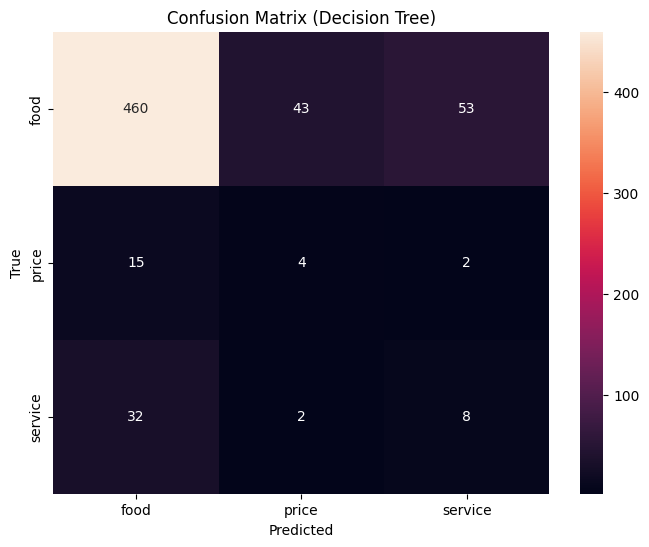

Predicted label: food


In [ ]:
!pip install seaborn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define X and y for classification
X = data['Comment']

# Choose target variable 'Aspect' or 'Sentiment'
y = data['Aspect']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create a Decision Tree pipeline
def create_dt_pipeline():
    return ImbPipeline([
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', DecisionTreeClassifier(random_state=42))  # Decision Tree classifier
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__max_depth': [10, 20, 30, None],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4],
    'clf__class_weight': ['balanced'],
    'clf__criterion': ['entropy']
}

# Create and tune the model with Grid Search
model_dt = create_dt_pipeline()
grid_search = GridSearchCV(model_dt, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_dt = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_dt, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_dt = best_model_dt.predict(X_test)
accuracy_dt = accuracy_score(y_test_int, predictions_dt)
print(f'Test Accuracy : {accuracy_dt:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_dt, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_dt = confusion_matrix(y_test_int, predictions_dt)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (Decision Tree)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with Decision Tree
def make_prediction_dt(comment):
    predicted_label_dt = best_model_dt.predict([comment])
    label_dt = label_encoder.inverse_transform(predicted_label_dt)
    print(f'Predicted label: {label_dt[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_dt(new_comment)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['conflict' 'negative' 'neutral' 'positive']
Best parameters: {'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 3}
Model cross-validation scores: [0.59461883 0.59156194 0.62926391 0.59335727 0.61041293]
Mean cross-validation score: 0.604
Test Accuracy : 0.611
Classification Report :
              precision    recall  f1-score   support

    conflict       0.18      0.28      0.22        39
    negative       0.81      0.68      0.74       380
     neutral       0.13      0.37      0.20        27
    positive       0.60      0.56      0.58       173

    accuracy                           0.61       619
   macro avg       0.43      0.47      0.43       619
weighted avg       0.68      0.61      0.64       6

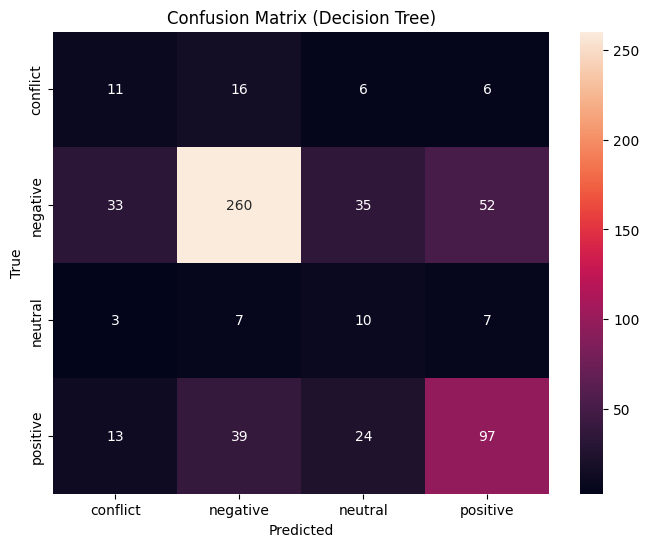

Predicted label: neutral


In [ ]:
!pip install emoji seaborn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

# Define X and y for classification
X = data['Comment']

y = data['Sentiment']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create a Decision Tree pipeline
def create_dt_pipeline():
    return ImbPipeline([
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', DecisionTreeClassifier(random_state=42))  # Decision Tree classifier
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__max_depth': [10, 20, 30, None],
    'clf__min_samples_split': [3, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4],
    'clf__class_weight': ['balanced'],
    'clf__criterion': ['entropy']
}

# Create and tune the model with Grid Search
model_dt = create_dt_pipeline()
grid_search = GridSearchCV(model_dt, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_dt = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_dt, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_dt = best_model_dt.predict(X_test)
accuracy_dt = accuracy_score(y_test_int, predictions_dt)
print(f'Test Accuracy : {accuracy_dt:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_dt, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_dt = confusion_matrix(y_test_int, predictions_dt)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (Decision Tree)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with Decision Tree
def make_prediction_dt(comment):
    predicted_label_dt = best_model_dt.predict([comment])
    label_dt = label_encoder.inverse_transform(predicted_label_dt)
    print(f'Predicted label: {label_dt[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_dt(new_comment)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['conflict' 'negative' 'neutral' 'positive']
Best parameters: {'clf__class_weight': 'balanced', 'clf__criterion': 'entropy', 'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 3}
Model cross-validation scores: [0.57399103 0.58976661 0.61938959 0.58348294 0.6032316 ]
Mean cross-validation score: 0.594
Test Accuracy : 0.604
Classification Report :
              precision    recall  f1-score   support

    conflict       0.19      0.26      0.22        39
    negative       0.80      0.67      0.73       380
     neutral       0.15      0.41      0.22        27
    positive       0.56      0.56      0.56       173

    accuracy                           0.60       619
   macro avg       0.42      0.47      0.43       619
weighted avg       0.67      0.60      0.63       6

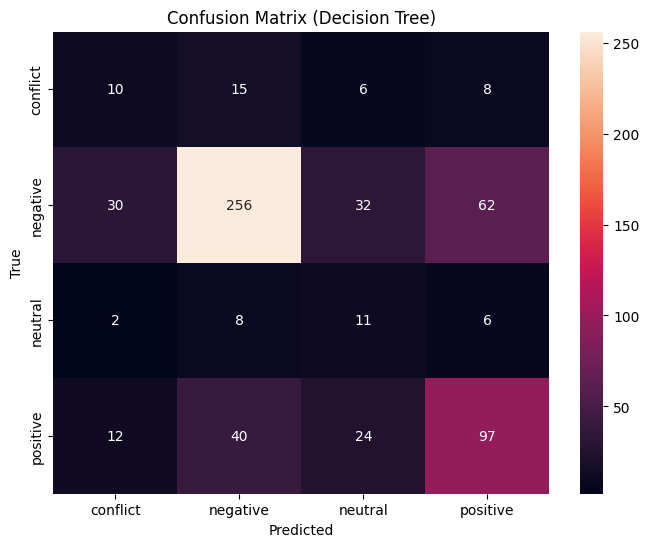

Predicted label: neutral


In [ ]:
!pip install seaborn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text

# Define X and y for classification
X = data['Comment']
y = data['Sentiment']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create a Decision Tree pipeline
def create_dt_pipeline():
    return ImbPipeline([
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', DecisionTreeClassifier(random_state=42))  # Decision Tree classifier
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__max_depth': [10, 20, 30, None],
    'clf__min_samples_split': [3, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4],
    'clf__class_weight': ['balanced'],
    'clf__criterion': ['entropy']
}

# Create and tune the model with Grid Search
model_dt = create_dt_pipeline()
grid_search = GridSearchCV(model_dt, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_dt = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_dt, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_dt = best_model_dt.predict(X_test)
accuracy_dt = accuracy_score(y_test_int, predictions_dt)
print(f'Test Accuracy : {accuracy_dt:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_dt, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_dt = confusion_matrix(y_test_int, predictions_dt)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (Decision Tree)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with Decision Tree
def make_prediction_dt(comment):
    predicted_label_dt = best_model_dt.predict([comment])
    label_dt = label_encoder.inverse_transform(predicted_label_dt)
    print(f'Predicted label: {label_dt[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_dt(new_comment)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['food' 'price' 'service']
Best parameters: {'clf__class_weight': 'balanced', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 5, 'clf__n_estimators': 200}
Model cross-validation scores: [0.82959641 0.84829443 0.8438061  0.83662478 0.8438061 ]
Mean cross-validation score: 0.840
Test Accuracy : 0.832
Classification Report :
              precision    recall  f1-score   support

        food       0.91      0.91      0.91       556
       price       0.13      0.19      0.15        21
     service       0.14      0.10      0.11        42

    accuracy                           0.83       619
   macro avg       0.39      0.40      0.39       619
weighted avg       0.83      0.83      0.83       619



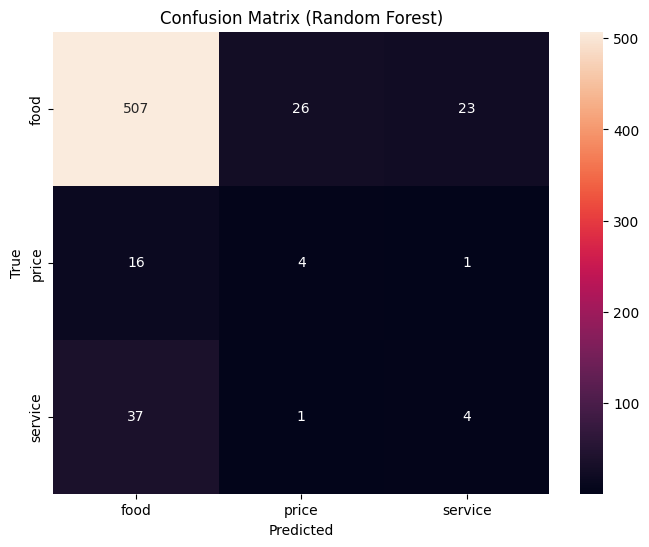

Predicted label: food


In [ ]:
!pip install emoji seaborn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

# Define X and y for classification
X = data['Comment']
y = data['Aspect']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-Fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create a Random Forest pipeline
def create_rf_pipeline():
    return ImbPipeline([
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', RandomForestClassifier(random_state=42))  # Random Forest classifier
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__n_estimators': [100 ,150, 200 ],
    'clf__max_features': ['sqrt'],
    'clf__max_depth': [None, 10, 20],
    'clf__min_samples_split': [2, 5],
    'clf__min_samples_leaf': [1, 2],
    'clf__class_weight': ['balanced']
}

# Create and tune the model with Grid Search
model_rf = create_rf_pipeline()
grid_search = GridSearchCV(model_rf, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_rf = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_rf, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_rf = best_model_rf.predict(X_test)
accuracy_rf = accuracy_score(y_test_int, predictions_rf)
print(f'Test Accuracy : {accuracy_rf:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_rf, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_rf = confusion_matrix(y_test_int, predictions_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (Random Forest)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with Random Forest
def make_prediction_rf(comment):
    predicted_label_rf = best_model_rf.predict([comment])
    label_rf = label_encoder.inverse_transform(predicted_label_rf)
    print(f'Predicted label: {label_rf[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_rf(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['food' 'price' 'service']
Best parameters: {'clf__class_weight': 'balanced', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 5, 'clf__n_estimators': 150}
Model cross-validation scores: [0.83497758 0.8438061  0.84111311 0.83303411 0.8438061 ]
Mean cross-validation score: 0.839
Test Accuracy : 0.837
Classification Report :
              precision    recall  f1-score   support

        food       0.91      0.92      0.91       556
       price       0.13      0.19      0.16        21
     service       0.18      0.12      0.14        42

    accuracy                           0.84       619
   macro avg       0.41      0.41      0.40       619
weighted avg       0.83      0.84      0.83       619



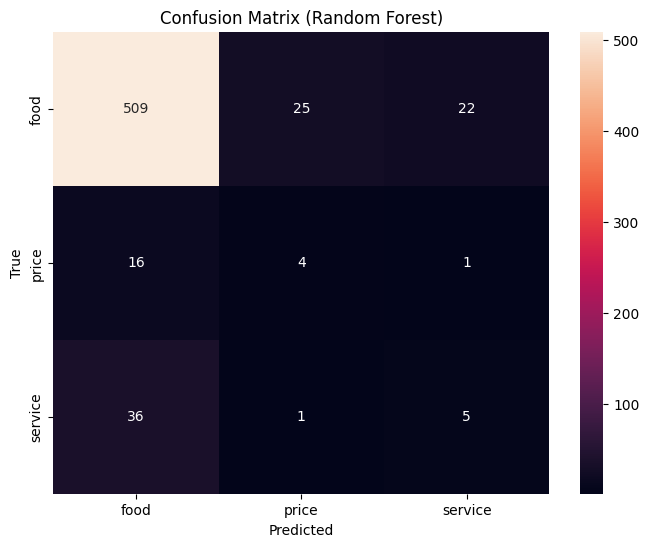

Predicted label: food


In [ ]:
!pip install seaborn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)


# Define X and y for classification
X = data['Comment']

# Choose target variable 'Aspect' or 'Sentiment'
y = data['Aspect']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-Fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create a Random Forest pipeline
def create_rf_pipeline():
    return ImbPipeline([
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', RandomForestClassifier(random_state=42))  # Random Forest classifier
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__n_estimators':  [100 , 150 ,200],
    'clf__max_features': ['sqrt'],
    'clf__max_depth': [None, 10, 20],
    'clf__min_samples_split': [2, 5],
    'clf__min_samples_leaf': [1, 2],
    'clf__class_weight': ['balanced']
}

# Create and tune the model with Grid Search
model_rf = create_rf_pipeline()
grid_search = GridSearchCV(model_rf, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_rf = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_rf, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_rf = best_model_rf.predict(X_test)
accuracy_rf = accuracy_score(y_test_int, predictions_rf)
print(f'Test Accuracy : {accuracy_rf:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_rf, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_rf = confusion_matrix(y_test_int, predictions_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (Random Forest)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with Random Forest
def make_prediction_rf(comment):
    predicted_label_rf = best_model_rf.predict([comment])
    label_rf = label_encoder.inverse_transform(predicted_label_rf)
    print(f'Predicted label: {label_rf[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_rf(new_comment)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['conflict' 'negative' 'neutral' 'positive']
Best parameters: {'clf__class_weight': 'balanced', 'clf__max_depth': 30, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2, 'clf__n_estimators': 100}
Model cross-validation scores: [0.70313901 0.69389587 0.72172352 0.6929982  0.73429084]
Mean cross-validation score: 0.709
Test Accuracy : 0.701
Classification Report :
              precision    recall  f1-score   support

    conflict       0.42      0.33      0.37        39
    negative       0.83      0.75      0.79       380
     neutral       0.47      0.26      0.33        27
    positive       0.56      0.74      0.64       173

    accuracy                           0.70       619
   macro avg       0.57      0.52      0.53       619
weighted avg       0.71    

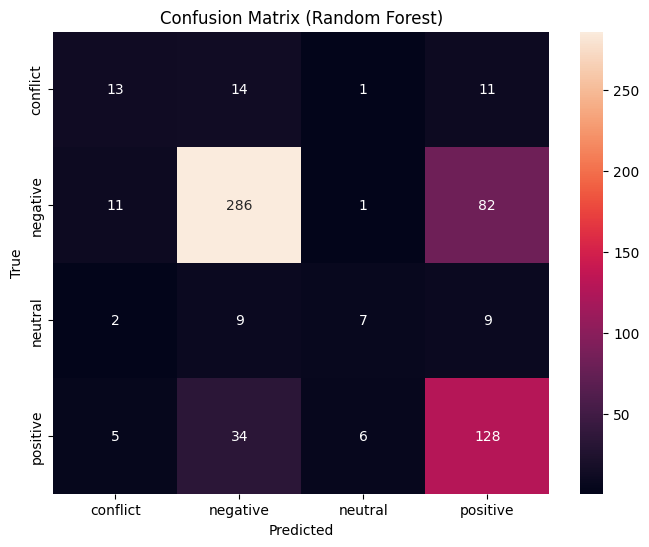

Predicted label: positive


In [ ]:
!pip install emoji seaborn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

# Define X and y for classification
X = data['Comment']
y = data['Sentiment']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-Fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create a Random Forest pipeline
def create_rf_pipeline():
    return ImbPipeline([
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', RandomForestClassifier(random_state=42))  # Random Forest classifier
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__n_estimators': [1, 10 ,50 , 100 ,150],
    'clf__max_features': ['sqrt'],
    'clf__max_depth': [30],
    'clf__min_samples_split': [2],
    'clf__min_samples_leaf': [1, 2],
    'clf__class_weight': ['balanced']
}

# Create and tune the model with Grid Search
model_rf = create_rf_pipeline()
grid_search = GridSearchCV(model_rf, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_rf = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_rf, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_rf = best_model_rf.predict(X_test)
accuracy_rf = accuracy_score(y_test_int, predictions_rf)
print(f'Test Accuracy : {accuracy_rf:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_rf, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_rf = confusion_matrix(y_test_int, predictions_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (Random Forest)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with Random Forest
def make_prediction_rf(comment):
    predicted_label_rf = best_model_rf.predict([comment])
    label_rf = label_encoder.inverse_transform(predicted_label_rf)
    print(f'Predicted label: {label_rf[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_rf(new_comment)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['conflict' 'negative' 'neutral' 'positive']
Best parameters: {'clf__class_weight': 'balanced', 'clf__max_depth': 30, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2, 'clf__n_estimators': 150}
Model cross-validation scores: [0.69058296 0.68581688 0.72710952 0.69389587 0.72531418]
Mean cross-validation score: 0.705
Test Accuracy : 0.696
Classification Report :
              precision    recall  f1-score   support

    conflict       0.45      0.36      0.40        39
    negative       0.82      0.75      0.78       380
     neutral       0.39      0.26      0.31        27
    positive       0.56      0.72      0.63       173

    accuracy                           0.70       619
   macro avg       0.56      0.52      0.53       619
weighted avg       0.71    

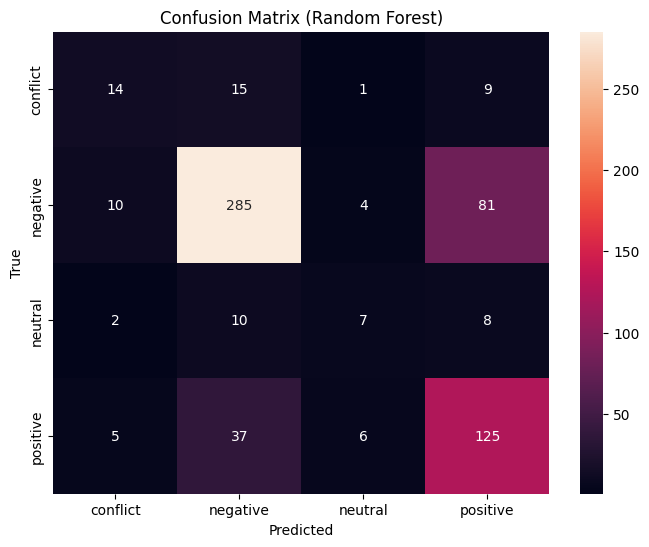

Predicted label: positive


In [ ]:
!pip install seaborn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define X and y for classification
X = data['Comment']
y = data['Sentiment']
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-Fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create a Random Forest pipeline
def create_rf_pipeline():
    return ImbPipeline([
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', RandomForestClassifier(random_state=42))  # Random Forest classifier
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__n_estimators': [1, 10 ,50 , 100 ,150],
    'clf__max_features': ['sqrt'],
    'clf__max_depth': [30],
    'clf__min_samples_split': [2],
    'clf__min_samples_leaf': [1, 2],
    'clf__class_weight': ['balanced']
}

# Create and tune the model with Grid Search
model_rf = create_rf_pipeline()
grid_search = GridSearchCV(model_rf, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_rf = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_rf, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_rf = best_model_rf.predict(X_test)
accuracy_rf = accuracy_score(y_test_int, predictions_rf)
print(f'Test Accuracy : {accuracy_rf:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_rf, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_rf = confusion_matrix(y_test_int, predictions_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (Random Forest)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with Random Forest
def make_prediction_rf(comment):
    predicted_label_rf = best_model_rf.predict([comment])
    label_rf = label_encoder.inverse_transform(predicted_label_rf)
    print(f'Predicted label: {label_rf[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_rf(new_comment)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['food' 'price' 'service']


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.080722 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 23923
[LightGBM] [Info] Number of data points in the train set: 14997, number of used features: 488
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
Best parameters: {'clf__learning_rate': 0.1, 'clf__max_depth': None, 'clf__n_estimators': 200, 'clf__num_leaves': 100}


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.066059 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20835
[LightGBM] [Info] Number of data points in the train set: 11997, number of used features: 440
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612


...

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.064207 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20063
[LightGBM] [Info] Number of data points in the train set: 12000, number of used features: 431
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Model cross-validation scores: [0.80538117 0.81149013 0.80789946 0.8070018  0.82854578]
Mean cross-validation score: 0.812
Test Accuracy : 0.801
Classification Report :
              precision    recall  f1-score   support

        food       0.91      0.87      0.89       556
       price       0.03      0.05      0.04        21
     service       0.17      0.21      0.19        42

    accuracy                           0.80       619
   macro avg       0.37      0.38      0.37       619
weighted avg       0.83      0.80      0.81       619



/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


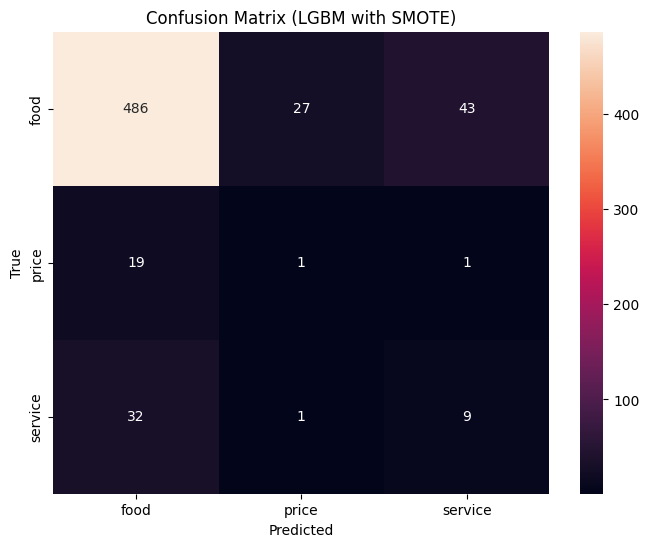

Predicted label: food


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
# Install necessary libraries
!pip install emoji seaborn lightgbm imbalanced-learn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)
# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

X = data['Comment']
y = data['Aspect']
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-Fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create an LGBM pipeline with SMOTE
def create_lgbm_pipeline_with_smote():
    return ImbPipeline([  # Use SMOTE for balancing the class distribution
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('smote', SMOTE(random_state=42)),  # Apply SMOTE to oversample minority class
        ('clf', LGBMClassifier(class_weight='balanced', random_state=42))  # LGBM classifier with class balancing
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__num_leaves': [50, 100],
    'clf__max_depth': [None, 10, 20],
    'clf__learning_rate': [0.1, 0.2],
    'clf__n_estimators': [100, 200]
}

# Create and tune the model with Grid Search
model_lgbm_smote = create_lgbm_pipeline_with_smote()
grid_search = GridSearchCV(model_lgbm_smote, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_lgbm_smote = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_lgbm_smote, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_lgbm_smote = best_model_lgbm_smote.predict(X_test)
accuracy_lgbm_smote = accuracy_score(y_test_int, predictions_lgbm_smote)
print(f'Test Accuracy : {accuracy_lgbm_smote:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_lgbm_smote, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_lgbm_smote = confusion_matrix(y_test_int, predictions_lgbm_smote)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lgbm_smote, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (LGBM with SMOTE)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with LGBM and SMOTE
def make_prediction_lgbm_smote(comment):
    predicted_label_lgbm_smote = best_model_lgbm_smote.predict([comment])
    label_lgbm_smote = label_encoder.inverse_transform(predicted_label_lgbm_smote)
    print(f'Predicted label: {label_lgbm_smote[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_lgbm_smote(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['food' 'price' 'service']


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.083661 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23115
[LightGBM] [Info] Number of data points in the train set: 14997, number of used features: 460
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] N

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.035721 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20604
[LightGBM] [Info] Number of data points in the train set: 11997, number of used features: 422
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further s

...

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.035060 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 18944
[LightGBM] [Info] Number of data points in the train set: 11997, number of used features: 412
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further s

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.034962 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19357
[LightGBM] [Info] Number of data points in the train set: 12000, number of used features: 407
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further s

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Model cross-validation scores: [0.81434978 0.81777379 0.8070018  0.8043088  0.83303411]
Mean cross-validation score: 0.815
Test Accuracy : 0.796
Classification Report :
              precision    recall  f1-score   support

        food       0.91      0.87      0.89       556
       price       0.08      0.14      0.11        21
     service       0.16      0.19      0.17        42

    accuracy                           0.80       619
   macro avg       0.38      0.40      0.39       619
weighted avg       0.83      0.80      0.81       619



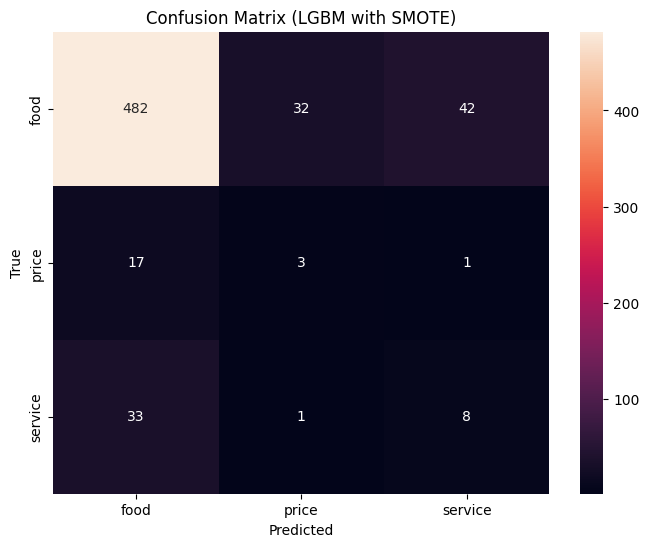

Predicted label: food


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
# Install necessary libraries
!pip install seaborn lightgbm imbalanced-learn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

X = data['Comment']
y = data['Aspect']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-Fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create an LGBM pipeline with SMOTE
def create_lgbm_pipeline_with_smote():
    return ImbPipeline([  # Use SMOTE for balancing the class distribution
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('smote', SMOTE(random_state=42)),  # Apply SMOTE to oversample minority class
        ('clf', LGBMClassifier(class_weight='balanced', random_state=42))  # LGBM classifier with class balancing
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__num_leaves': [50, 100],
    'clf__max_depth': [None, 10, 20],
    'clf__learning_rate': [0.1, 0.2],
    'clf__n_estimators': [100, 200]
}

# Create and tune the model with Grid Search
model_lgbm_smote = create_lgbm_pipeline_with_smote()
grid_search = GridSearchCV(model_lgbm_smote, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_lgbm_smote = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_lgbm_smote, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_lgbm_smote = best_model_lgbm_smote.predict(X_test)
accuracy_lgbm_smote = accuracy_score(y_test_int, predictions_lgbm_smote)
print(f'Test Accuracy : {accuracy_lgbm_smote:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_lgbm_smote, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_lgbm_smote = confusion_matrix(y_test_int, predictions_lgbm_smote)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lgbm_smote, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (LGBM with SMOTE)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with LGBM and SMOTE
def make_prediction_lgbm_smote(comment):
    predicted_label_lgbm_smote = best_model_lgbm_smote.predict([comment])
    label_lgbm_smote = label_encoder.inverse_transform(predicted_label_lgbm_smote)
    print(f'Predicted label: {label_lgbm_smote[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_lgbm_smote(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['food' 'price' 'service']


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.047368 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23115
[LightGBM] [Info] Number of data points in the train set: 14997, number of used features: 460
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] N

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.070448 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20604
[LightGBM] [Info] Number of data points in the train set: 11997, number of used features: 422
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further s

...

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.033417 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 19357
[LightGBM] [Info] Number of data points in the train set: 12000, number of used features: 407
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further s

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Model cross-validation scores: [0.81434978 0.81777379 0.8070018  0.8043088  0.83303411]
Mean cross-validation score: 0.815
Test Accuracy : 0.796
Classification Report :
              precision    recall  f1-score   support

        food       0.91      0.87      0.89       556
       price       0.08      0.14      0.11        21
     service       0.16      0.19      0.17        42

    accuracy                           0.80       619
   macro avg       0.38      0.40      0.39       619
weighted avg       0.83      0.80      0.81       619



/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


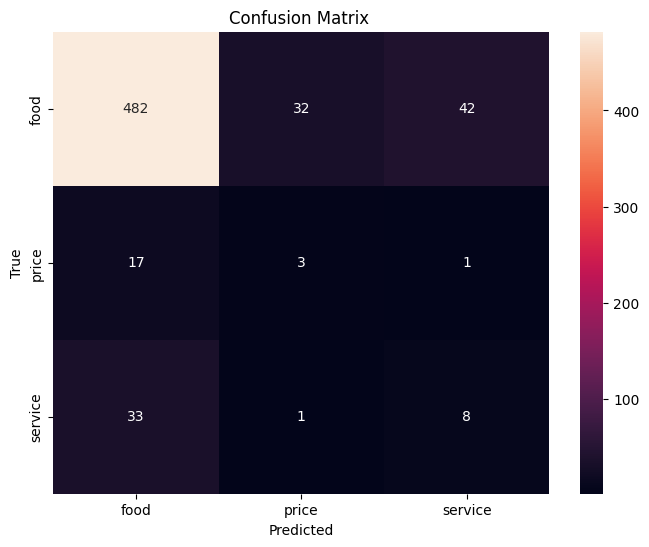

Predicted label: food


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
# Install necessary libraries
!pip install  seaborn lightgbm imbalanced-learn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE  # Import SMOTE for over-sampling
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define X and y for classification (Choose 'Aspect' or 'Sentiment' as the target variable)
X = data['Comment']
y = data['Aspect']  # Change this to 'Aspect' if you want Aspect classification

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-Fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create an LGBM pipeline with SMOTE
def create_lgbm_pipeline_with_smote():
    return ImbPipeline([  # Use SMOTE for balancing the class distribution
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('smote', SMOTE(random_state=42)),  # Apply SMOTE to oversample minority class
        ('clf', LGBMClassifier(class_weight='balanced', random_state=42))  # LGBM classifier with class balancing
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__num_leaves': [50, 100],
    'clf__max_depth': [None, 10, 20],
    'clf__learning_rate': [0.1, 0.2],
    'clf__n_estimators': [100, 200]
}

# Create and tune the model with Grid Search
model_lgbm_smote = create_lgbm_pipeline_with_smote()
grid_search = GridSearchCV(model_lgbm_smote, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_lgbm_smote = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_lgbm_smote, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_lgbm_smote = best_model_lgbm_smote.predict(X_test)
accuracy_lgbm_smote = accuracy_score(y_test_int, predictions_lgbm_smote)
print(f'Test Accuracy : {accuracy_lgbm_smote:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_lgbm_smote, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_lgbm_smote = confusion_matrix(y_test_int, predictions_lgbm_smote)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lgbm_smote, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix ')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with LGBM and SMOTE
def make_prediction_lgbm_smote(comment):
    predicted_label_lgbm_smote = best_model_lgbm_smote.predict([comment])
    label_lgbm_smote = label_encoder.inverse_transform(predicted_label_lgbm_smote)
    print(f'Predicted label: {label_lgbm_smote[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_lgbm_smote(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['conflict' 'negative' 'neutral' 'positive']


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.069032 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 20624
[LightGBM] [Info] Number of data points in the train set: 13672, number of used features: 403
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
Best parameters: {'clf__learning_rate': 0.1, 'clf__max_depth': None, 'clf__n_estimators': 100, 'clf__num_leaves': 100}


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.031653 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 17487
[LightGBM] [Info] Number of data points in the train set: 10940, number of used features: 367
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294


...

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.028796 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17569
[LightGBM] [Info] Number of data points in the train set: 10936, number of used features: 379
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.046851 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17903
[LightGBM] [Info] Number of data points in the train set: 10936, number of used features: 372
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Model cross-validation scores: [0.69596413 0.67504488 0.73608618 0.68671454 0.71364452]
Mean cross-validation score: 0.701
Test Accuracy : 0.680
Classification Report :
              precision    recall  f1-score   support

    conflict       0.24      0.28      0.26        39
    negative       0.83      0.76      0.79       380
     neutral       0.17      0.37      0.23        27
    positive       0.66      0.65      0.65       173

    accuracy                           0.68       619
   macro avg       0.48      0.51      0.49       619
weighted avg       0.72      0.68      0.70       619



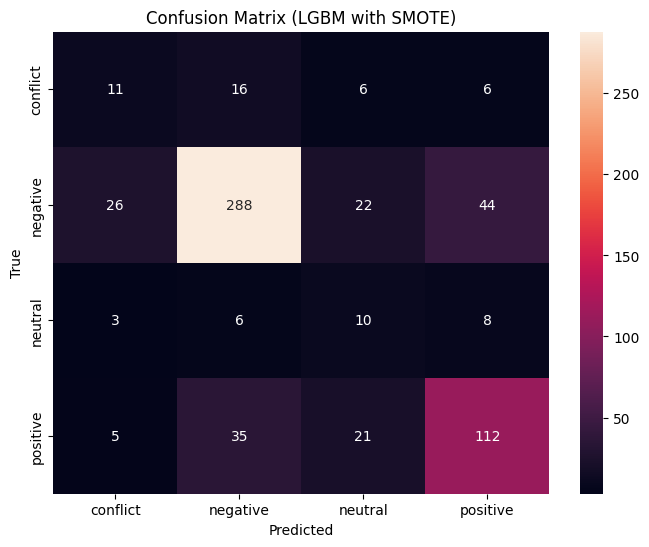

Predicted label: neutral


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
# Install necessary libraries
!pip install emoji seaborn lightgbm imbalanced-learn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE  # Import SMOTE for over-sampling
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

# Define X and y for classification (Choose 'Aspect' or 'Sentiment' as the target variable)
X = data['Comment']
y = data['Sentiment']  # Change this to 'Aspect' if you want Aspect classification

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-Fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create an LGBM pipeline with SMOTE
def create_lgbm_pipeline_with_smote():
    return ImbPipeline([  # Use SMOTE for balancing the class distribution
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('smote', SMOTE(random_state=42)),  # Apply SMOTE to oversample minority class
        ('clf', LGBMClassifier(class_weight='balanced', random_state=42))  # LGBM classifier with class balancing
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__num_leaves': [50, 100],
    'clf__max_depth': [None, 10, 20],
    'clf__learning_rate': [0.1, 0.2],
    'clf__n_estimators': [100, 200]
}

# Create and tune the model with Grid Search
model_lgbm_smote = create_lgbm_pipeline_with_smote()
grid_search = GridSearchCV(model_lgbm_smote, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_lgbm_smote = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_lgbm_smote, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_lgbm_smote = best_model_lgbm_smote.predict(X_test)
accuracy_lgbm_smote = accuracy_score(y_test_int, predictions_lgbm_smote)
print(f'Test Accuracy : {accuracy_lgbm_smote:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_lgbm_smote, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_lgbm_smote = confusion_matrix(y_test_int, predictions_lgbm_smote)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lgbm_smote, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (LGBM with SMOTE)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with LGBM and SMOTE
def make_prediction_lgbm_smote(comment):
    predicted_label_lgbm_smote = best_model_lgbm_smote.predict([comment])
    label_lgbm_smote = label_encoder.inverse_transform(predicted_label_lgbm_smote)
    print(f'Predicted label: {label_lgbm_smote[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_lgbm_smote(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['conflict' 'negative' 'neutral' 'positive']


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.058702 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 20133
[LightGBM] [Info] Number of data points in the train set: 13672, number of used features: 382
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
Best parameters: {'clf__learning_rate': 0.1, 'clf__max_depth': None, 'clf__n_estimators': 100, 'clf__num_leaves': 50}


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.027043 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17138
[LightGBM] [Info] Number of data points in the train set: 10940, number of used features: 346
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294


...

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.041440 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17268
[LightGBM] [Info] Number of data points in the train set: 10936, number of used features: 361
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.027376 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 17569
[LightGBM] [Info] Number of data points in the train set: 10936, number of used features: 357
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Model cross-validation scores: [0.6690583  0.66517056 0.73249551 0.68402154 0.7010772 ]
Mean cross-validation score: 0.690
Test Accuracy : 0.698
Classification Report :
              precision    recall  f1-score   support

    conflict       0.29      0.38      0.33        39
    negative       0.86      0.77      0.81       380
     neutral       0.16      0.37      0.23        27
    positive       0.69      0.67      0.68       173

    accuracy                           0.70       619
   macro avg       0.50      0.55      0.51       619
weighted avg       0.75      0.70      0.72       619



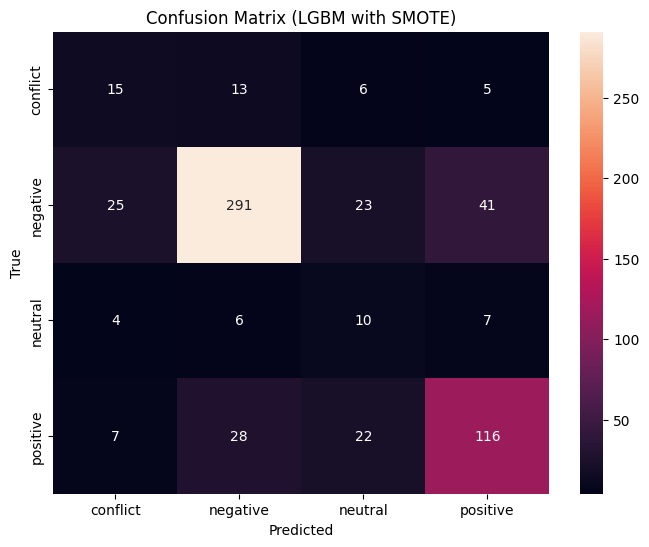

Predicted label: neutral


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
# Install necessary libraries
!pip install seaborn lightgbm imbalanced-learn

# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE  # Import SMOTE for over-sampling
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from google.colab import drive
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)


# Define X and y for classification (Choose 'Aspect' or 'Sentiment' as the target variable)
X = data['Comment']
y = data['Sentiment']  # Change this to 'Aspect' if you want Aspect classification

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Define Stratified K-Fold cross-validation (e.g., 5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define a function to create an LGBM pipeline with SMOTE
def create_lgbm_pipeline_with_smote():
    return ImbPipeline([  # Use SMOTE for balancing the class distribution
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('smote', SMOTE(random_state=42)),  # Apply SMOTE to oversample minority class
        ('clf', LGBMClassifier(class_weight='balanced', random_state=42))  # LGBM classifier with class balancing
    ])

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'clf__num_leaves': [50, 100],
    'clf__max_depth': [None, 10, 20],
    'clf__learning_rate': [0.1, 0.2],
    'clf__n_estimators': [100, 200]
}

# Create and tune the model with Grid Search
model_lgbm_smote = create_lgbm_pipeline_with_smote()
grid_search = GridSearchCV(model_lgbm_smote, param_grid, cv=stratified_kf, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train_int)

# Output the best parameters and score for the model
print("Best parameters:", grid_search.best_params_)

# Get the best estimator from the grid search
best_model_lgbm_smote = grid_search.best_estimator_

# Perform Stratified K-Fold Cross-validation for the model
cross_val_scores = cross_val_score(best_model_lgbm_smote, X_train, y_train_int, cv=stratified_kf, scoring='accuracy')
print(f'Model cross-validation scores: {cross_val_scores}')
print(f'Mean cross-validation score: {cross_val_scores.mean():.3f}')

# Evaluate the model
predictions_lgbm_smote = best_model_lgbm_smote.predict(X_test)
accuracy_lgbm_smote = accuracy_score(y_test_int, predictions_lgbm_smote)
print(f'Test Accuracy : {accuracy_lgbm_smote:.3f}')
print('Classification Report :')
print(classification_report(y_test_int, predictions_lgbm_smote, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm_lgbm_smote = confusion_matrix(y_test_int, predictions_lgbm_smote)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lgbm_smote, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix (LGBM with SMOTE)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions with LGBM and SMOTE
def make_prediction_lgbm_smote(comment):
    predicted_label_lgbm_smote = best_model_lgbm_smote.predict([comment])
    label_lgbm_smote = label_encoder.inverse_transform(predicted_label_lgbm_smote)
    print(f'Predicted label: {label_lgbm_smote[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction_lgbm_smote(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Classes: ['food' 'price' 'service']
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters:  {'clf__estimator__max_depth': None, 'clf__estimator__min_samples_split': 2, 'clf__n_estimators': 50}
Cross-Validation Scores: [0.80807175 0.82764811 0.82315978 0.81149013 0.82046679]
Mean Cross-Validation Score: 0.818
Test Accuracy: 0.803
Classification Report:
              precision    recall  f1-score   support

        food       0.91      0.87      0.89       556
       price       0.09      0.19      0.12        21
     service       0.19      0.17      0.18        42

    accuracy                           0.80       619
   macro avg       0.39      0.41      0.40       619
weighted avg       0.83      0.80      0.82       619



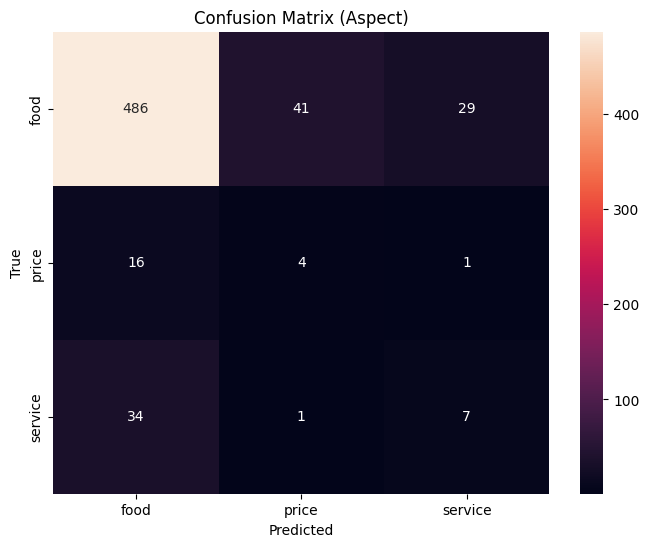

Predicted label: food


In [ ]:
# Install necessary libraries
!pip install emoji seaborn

# Import necessary libraries
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

# Choose which target variable to classify: 'Aspect' or 'Sentiment'
target_column = 'Aspect'  # Change to 'Aspect' to classify Aspect instead of Sentiment

# Split data into training and testing sets
train_comments, test_comments, train_target, test_target = train_test_split(
    data['Comment'], data[target_column], test_size=0.1, random_state=42, stratify=data[target_column]
)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
train_target_int = label_encoder.fit_transform(train_target)
test_target_int = label_encoder.transform(test_target)

print(f"Classes: {label_encoder.classes_}")

# Define a function to create a Bagging pipeline with Decision Tree
def create_bagging_pipeline():
    return Pipeline([
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', BaggingClassifier(
            estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),  # Use Decision Tree with balanced class weights
            random_state=42
        ))
    ])

# Set up the parameter grid for hyperparameter tuning
param_grid = {
    'clf__n_estimators': [10, 20, 50],  # Number of base estimators
    'clf__estimator__max_depth': [None, 10, 20],  # Maximum depth of the tree
    'clf__estimator__min_samples_split': [2, 5],  # Minimum samples required to split an internal node
}

# Define the Stratified K-Fold cross-validation (5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Perform Grid Search with Stratified K-Fold Cross-Validation for Classification Model
grid_search = GridSearchCV(create_bagging_pipeline(), param_grid, cv=stratified_kf, n_jobs=-1, verbose=1)
grid_search.fit(train_comments, train_target_int)

# Best parameters found for classification
print("Best parameters: ", grid_search.best_params_)

# Get Cross-validation Scores for the classification model
cv_scores = cross_val_score(grid_search.best_estimator_, train_comments, train_target_int, cv=stratified_kf)
print(f"Cross-Validation Scores: {cv_scores}")
print(f"Mean Cross-Validation Score: {cv_scores.mean():.3f}")

# Create and train the classification model with the best parameters
best_model = grid_search.best_estimator_
best_model.fit(train_comments, train_target_int)

# Evaluate the model
predictions = best_model.predict(test_comments)
accuracy = accuracy_score(test_target_int, predictions)
print(f'Test Accuracy: {accuracy:.3f}')
print('Classification Report:')
print(classification_report(test_target_int, predictions, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm = confusion_matrix(test_target_int, predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title(f'Confusion Matrix ({target_column})')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions
def make_prediction(comment):
    predicted_label = best_model.predict([comment])
    label = label_encoder.inverse_transform(predicted_label)
    print(f'Predicted label: {label[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Classes: ['food' 'price' 'service']
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters:  {'clf__estimator__max_depth': None, 'clf__estimator__min_samples_split': 2, 'clf__n_estimators': 20}
Cross-Validation Scores: [0.80896861 0.82405745 0.82136445 0.81238779 0.82046679]
Mean Cross-Validation Score: 0.817
Test Accuracy: 0.803
Classification Report:
              precision    recall  f1-score   support

        food       0.91      0.88      0.89       556
       price       0.09      0.19      0.12        21
     service       0.16      0.14      0.15        42

    accuracy                           0.80       619
   macro avg       0.39      0.40      0.39       619
weighted avg       0.83      0.80      0.81       619



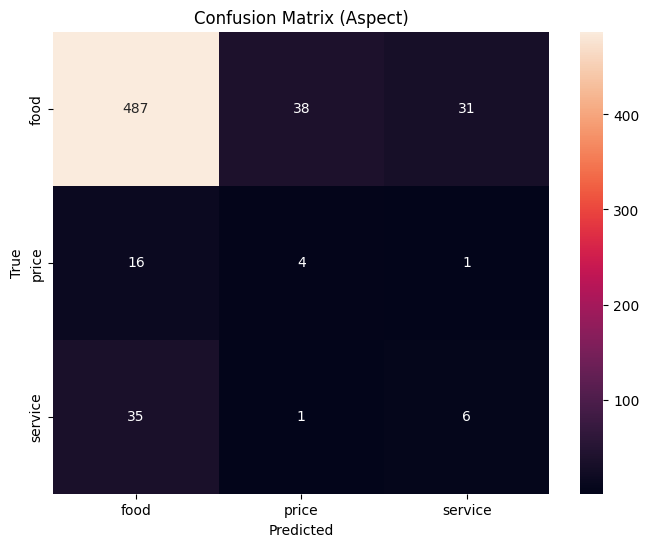

Predicted label: food


In [ ]:
# Install necessary libraries
!pip install seaborn

# Import necessary libraries
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Choose which target variable to classify: 'Aspect' or 'Sentiment'
target_column = 'Aspect'  # Change to 'Aspect' to classify Aspect instead of Sentiment

# Split data into training and testing sets
train_comments, test_comments, train_target, test_target = train_test_split(
    data['Comment'], data[target_column], test_size=0.1, random_state=42, stratify=data[target_column]
)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
train_target_int = label_encoder.fit_transform(train_target)
test_target_int = label_encoder.transform(test_target)

print(f"Classes: {label_encoder.classes_}")

# Define a function to create a Bagging pipeline with Decision Tree
def create_bagging_pipeline():
    return Pipeline([
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', BaggingClassifier(
            estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),  # Use Decision Tree with balanced class weights
            random_state=42
        ))
    ])

# Set up the parameter grid for hyperparameter tuning
param_grid = {
    'clf__n_estimators': [10, 20, 50],  # Number of base estimators
    'clf__estimator__max_depth': [None, 10, 20],  # Maximum depth of the tree
    'clf__estimator__min_samples_split': [2, 5],  # Minimum samples required to split an internal node
}

# Define the Stratified K-Fold cross-validation (5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Perform Grid Search with Stratified K-Fold Cross-Validation for Classification Model
grid_search = GridSearchCV(create_bagging_pipeline(), param_grid, cv=stratified_kf, n_jobs=-1, verbose=1)
grid_search.fit(train_comments, train_target_int)

# Best parameters found for classification
print("Best parameters: ", grid_search.best_params_)

# Get Cross-validation Scores for the classification model
cv_scores = cross_val_score(grid_search.best_estimator_, train_comments, train_target_int, cv=stratified_kf)
print(f"Cross-Validation Scores: {cv_scores}")
print(f"Mean Cross-Validation Score: {cv_scores.mean():.3f}")

# Create and train the classification model with the best parameters
best_model = grid_search.best_estimator_
best_model.fit(train_comments, train_target_int)

# Evaluate the model
predictions = best_model.predict(test_comments)
accuracy = accuracy_score(test_target_int, predictions)
print(f'Test Accuracy: {accuracy:.3f}')
print('Classification Report:')
print(classification_report(test_target_int, predictions, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm = confusion_matrix(test_target_int, predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title(f'Confusion Matrix ({target_column})')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions
def make_prediction(comment):
    predicted_label = best_model.predict([comment])
    label = label_encoder.inverse_transform(predicted_label)
    print(f'Predicted label: {label[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Classes: ['conflict' 'negative' 'neutral' 'positive']
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters:  {'clf__estimator__max_depth': None, 'clf__estimator__min_samples_split': 2, 'clf__n_estimators': 50}
Test Accuracy: 0.693
Classification Report:
              precision    recall  f1-score   support

    conflict       0.32      0.33      0.33        39
    negative       0.83      0.80      0.81       380
     neutral       0.16      0.41      0.23        27
    positive       0.71      0.58      0.64       173

    accuracy                           0.69       619
   macro avg       0.50      0.53      0.50       619
weighted avg       0.73      0.69      0.71       619



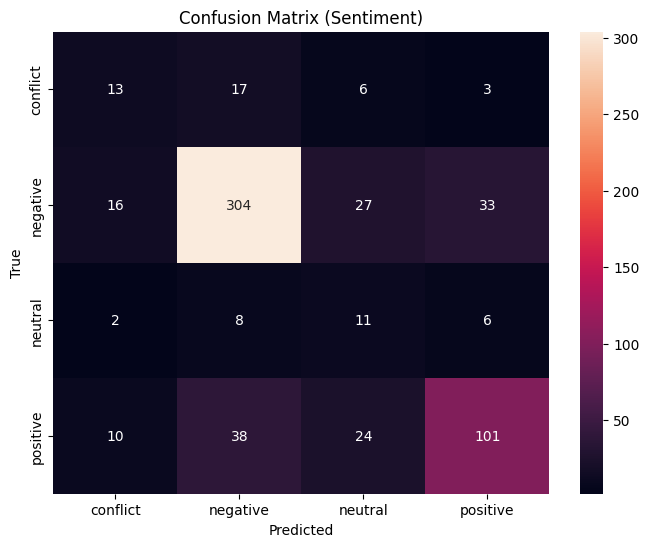

Predicted label: neutral


In [ ]:
# Install necessary libraries
!pip install emoji seaborn

# Import necessary libraries
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

# Choose which target variable to classify: 'Aspect' or 'Sentiment'
target_column = 'Sentiment'  # Change to 'Aspect' to classify Aspect instead of Sentiment

# Split data into training and testing sets
train_comments, test_comments, train_target, test_target = train_test_split(
    data['Comment'], data[target_column], test_size=0.1, random_state=42, stratify=data[target_column]
)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
train_target_int = label_encoder.fit_transform(train_target)
test_target_int = label_encoder.transform(test_target)

print(f"Classes: {label_encoder.classes_}")

# Define a function to create a Bagging pipeline with Decision Tree
def create_bagging_pipeline():
    return Pipeline([
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', BaggingClassifier(
            estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),  # Use Decision Tree with balanced class weights
            random_state=42
        ))
    ])

# Set up the parameter grid for hyperparameter tuning
param_grid = {
    'clf__n_estimators': [10, 20, 50],  # Number of base estimators
    'clf__estimator__max_depth': [None, 10, 20],  # Maximum depth of the tree
    'clf__estimator__min_samples_split': [2, 5],  # Minimum samples required to split an internal node
}

# Define the Stratified K-Fold cross-validation (5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Perform Grid Search with Stratified K-Fold Cross-Validation for Classification Model
grid_search = GridSearchCV(create_bagging_pipeline(), param_grid, cv=stratified_kf, n_jobs=-1, verbose=1)
grid_search.fit(train_comments, train_target_int)

# Best parameters found for classification
print("Best parameters: ", grid_search.best_params_)

# Get Cross-validation Scores for the classification model
cv_scores = cross_val_score(grid_search.best_estimator_, train_comments, train_target_int, cv=stratified_kf)
print(f"Cross-Validation Scores: {cv_scores}")
print(f"Mean Cross-Validation Score: {cv_scores.mean():.3f}")

# Create and train the classification model with the best parameters
best_model = grid_search.best_estimator_
best_model.fit(train_comments, train_target_int)

# Evaluate the model
predictions = best_model.predict(test_comments)
accuracy = accuracy_score(test_target_int, predictions)
print(f'Test Accuracy: {accuracy:.3f}')
print('Classification Report:')
print(classification_report(test_target_int, predictions, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm = confusion_matrix(test_target_int, predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title(f'Confusion Matrix ({target_column})')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions
def make_prediction(comment):
    predicted_label = best_model.predict([comment])
    label = label_encoder.inverse_transform(predicted_label)
    print(f'Predicted label: {label[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Classes: ['conflict' 'negative' 'neutral' 'positive']
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters:  {'clf__estimator__max_depth': None, 'clf__estimator__min_samples_split': 2, 'clf__n_estimators': 50}
Cross-Validation Scores: [0.65381166 0.65798923 0.6983842  0.66696589 0.67863555]
Mean Cross-Validation Score: 0.671
Test Accuracy: 0.683
Classification Report:
              precision    recall  f1-score   support

    conflict       0.28      0.28      0.28        39
    negative       0.82      0.78      0.80       380
     neutral       0.17      0.44      0.24        27
    positive       0.69      0.60      0.64       173

    accuracy                           0.68       619
   macro avg       0.49      0.53      0.49       619
weighted avg       0.72      0.68      0.70       619



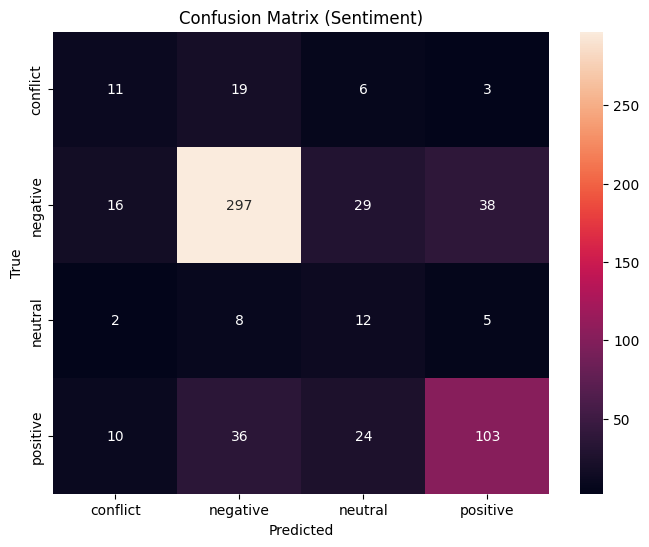

Predicted label: neutral


In [ ]:
# Install necessary libraries
!pip install seaborn

# Import necessary libraries
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Choose which target variable to classify: 'Aspect' or 'Sentiment'
target_column = 'Sentiment'  # Change to 'Aspect' to classify Aspect instead of Sentiment

# Split data into training and testing sets
train_comments, test_comments, train_target, test_target = train_test_split(
    data['Comment'], data[target_column], test_size=0.1, random_state=42, stratify=data[target_column]
)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
train_target_int = label_encoder.fit_transform(train_target)
test_target_int = label_encoder.transform(test_target)

print(f"Classes: {label_encoder.classes_}")

# Define a function to create a Bagging pipeline with Decision Tree
def create_bagging_pipeline():
    return Pipeline([
        ('vect', TfidfVectorizer()),  # Convert text to term-frequency-inverse-document-frequency matrix
        ('clf', BaggingClassifier(
            estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),  # Use Decision Tree with balanced class weights
            random_state=42
        ))
    ])

# Set up the parameter grid for hyperparameter tuning
param_grid = {
    'clf__n_estimators': [10, 20, 50],  # Number of base estimators
    'clf__estimator__max_depth': [None, 10, 20],  # Maximum depth of the tree
    'clf__estimator__min_samples_split': [2, 5],  # Minimum samples required to split an internal node
}

# Define the Stratified K-Fold cross-validation (5-fold)
stratified_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Perform Grid Search with Stratified K-Fold Cross-Validation for Classification Model
grid_search = GridSearchCV(create_bagging_pipeline(), param_grid, cv=stratified_kf, n_jobs=-1, verbose=1)
grid_search.fit(train_comments, train_target_int)

# Best parameters found for classification
print("Best parameters: ", grid_search.best_params_)

# Get Cross-validation Scores for the classification model
cv_scores = cross_val_score(grid_search.best_estimator_, train_comments, train_target_int, cv=stratified_kf)
print(f"Cross-Validation Scores: {cv_scores}")
print(f"Mean Cross-Validation Score: {cv_scores.mean():.3f}")

# Create and train the classification model with the best parameters
best_model = grid_search.best_estimator_
best_model.fit(train_comments, train_target_int)

# Evaluate the model
predictions = best_model.predict(test_comments)
accuracy = accuracy_score(test_target_int, predictions)
print(f'Test Accuracy: {accuracy:.3f}')
print('Classification Report:')
print(classification_report(test_target_int, predictions, target_names=label_encoder.classes_, zero_division=0))

# Plot confusion matrix using seaborn heatmap
cm = confusion_matrix(test_target_int, predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title(f'Confusion Matrix ({target_column})')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Define a function to make predictions
def make_prediction(comment):
    predicted_label = best_model.predict([comment])
    label = label_encoder.inverse_transform(predicted_label)
    print(f'Predicted label: {label[0]}')

# Test the function with a new comment
new_comment = 'ভালো ছিল'
make_prediction(new_comment)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 81s 215ms/step - accuracy: 0.5169 - loss: 0.9943 - val_accuracy: 0.5299 - val_loss: 1.1007
Epoch 2/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 56s 179ms/step - accuracy: 0.8026 - loss: 0.4712 - val_accuracy: 0.7512 - val_loss: 0.7849
Epoch 3/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 83s 181ms/step - accuracy: 0.8716 - loss: 0.2729 - val_accuracy: 0.8288 - val_loss: 0.5629
Epoch 4/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 53s 172ms/step - accuracy: 0.9041 - loss: 0.2325 - val_accuracy: 0.8271 - val_loss: 0.5835
Epoch 5/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 54s 175ms/step - accuracy: 0.9164 - loss: 0.2029 - val_accuracy: 0.7706 - val_loss: 0.7100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.8255 - loss: 0.5562
Test Loss: 0.5644018054008484, Test Accuracy: 0.8255250453948975
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 142ms/step
Classification Accuracy: 0.8255
Classific

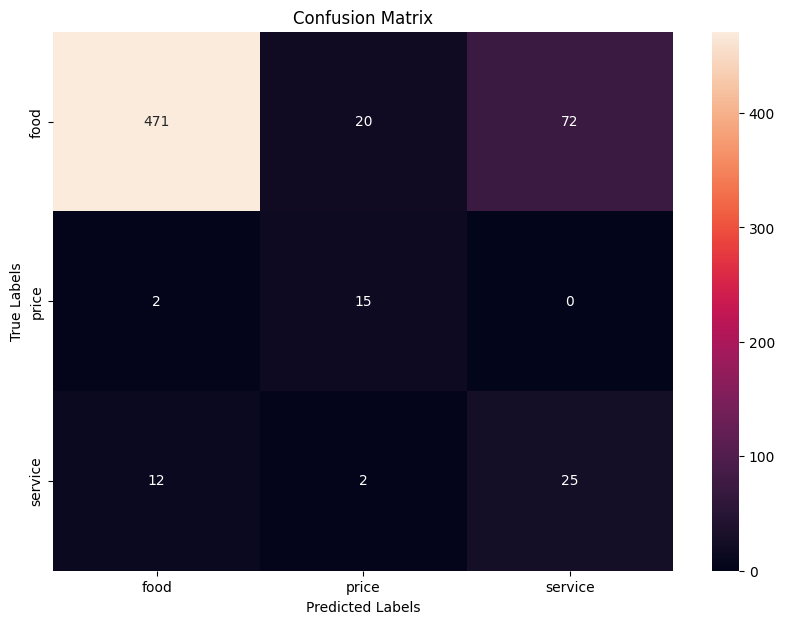

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Predicted Label: food


In [ ]:
!pip install emoji
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Bidirectional
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import emoji
import pandas as pd
import random
import os
from google.colab import drive
from sklearn.preprocessing import LabelEncoder
from sklearn.utils import class_weight
from sklearn.metrics import accuracy_score
from tensorflow.keras.callbacks import EarlyStopping


# Mount Google Drive
drive.mount('/content/drive')

# Set seed for reproducibility
seed_value = 42
np.random.seed(seed_value)
random.seed(seed_value)
tf.random.set_seed(seed_value)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Load the dataset
data_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
df = pd.read_excel(data_path)

# Emoji processing function
def demojize_text(text):
    return emoji.demojize(text)

df['Comment'] = df['Comment'].apply(demojize_text)

X = df['Comment']
y = df['Aspect']

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into 80% training, 10% validation, and 10% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=seed_value)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=seed_value)

# Tokenization and Padding
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len)

# Calculate class weights for class imbalance
class_weights = class_weight.compute_class_weight(
    'balanced', classes=np.unique(y_train), y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))

# Model parameters
embedding_dim = 256
num_classes = len(label_encoder.classes_)

# BiLSTM Model
input_layer = Input(shape=(max_len,))
embedding_layer = Embedding(max_words, embedding_dim)(input_layer)
bilstm_layer = Bidirectional(LSTM(64, return_sequences=False))(embedding_layer)
output_layer = Dense(num_classes, activation='softmax')(bilstm_layer)

model = Model(inputs=input_layer, outputs=output_layer)

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the model with validation, class weights, and early stopping
history = model.fit(
    X_train_pad, y_train,
    epochs=5,
    batch_size=16,
    validation_data=(X_val_pad, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

# Evaluate the model on the test set
results = model.evaluate(X_test_pad, y_test)
print(f'Test Loss: {results[0]}, Test Accuracy: {results[1]}')

y_pred = model.predict(X_test_pad).argmax(axis=1)

# Classification accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Classification Accuracy: {accuracy:.4f}')

# Classification report
report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)
print("Classification Report:")
print(report)

# Confusion Matrix with Seaborn Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Function to predict new comments
def predict_new_comment(new_comment, model, tokenizer, label_encoder, max_len=100):
    # Step 1: Preprocess the new comment (demojize, tokenize, and pad)
    new_comment_demojized = demojize_text(new_comment)  # Convert emojis to text
    new_comment_seq = tokenizer.texts_to_sequences([new_comment_demojized])  # Tokenize
    new_comment_pad = pad_sequences(new_comment_seq, maxlen=max_len)  # Pad sequence

    # Step 2: Predict using the trained model
    prediction = model.predict(new_comment_pad).argmax(axis=1)  # Prediction
    predicted_label = label_encoder.inverse_transform(prediction)  # Convert back to original label

    # Step 3: Return the prediction
    return predicted_label[0]

# Example usage:
new_comment = "খুবই ভালো ছিল"
predicted_label = predict_new_comment(new_comment, model, tokenizer, label_encoder)
print(f"Predicted Label: {predicted_label}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 81s 215ms/step - accuracy: 0.5170 - loss: 0.9954 - val_accuracy: 0.6042 - val_loss: 1.0023
Epoch 2/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 73s 187ms/step - accuracy: 0.8094 - loss: 0.4717 - val_accuracy: 0.8078 - val_loss: 0.5904
Epoch 3/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 82s 187ms/step - accuracy: 0.8819 - loss: 0.2555 - val_accuracy: 0.8094 - val_loss: 0.5962
Epoch 4/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 59s 191ms/step - accuracy: 0.9021 - loss: 0.2075 - val_accuracy: 0.8401 - val_loss: 0.5674
Epoch 5/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 77s 174ms/step - accuracy: 0.9210 - loss: 0.1901 - val_accuracy: 0.8352 - val_loss: 0.6067
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - accuracy: 0.8338 - loss: 0.5553
Test Loss: 0.5389028191566467, Test Accuracy: 0.8303715586662292
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 154ms/step
Classification Accuracy: 0.8304
Classific

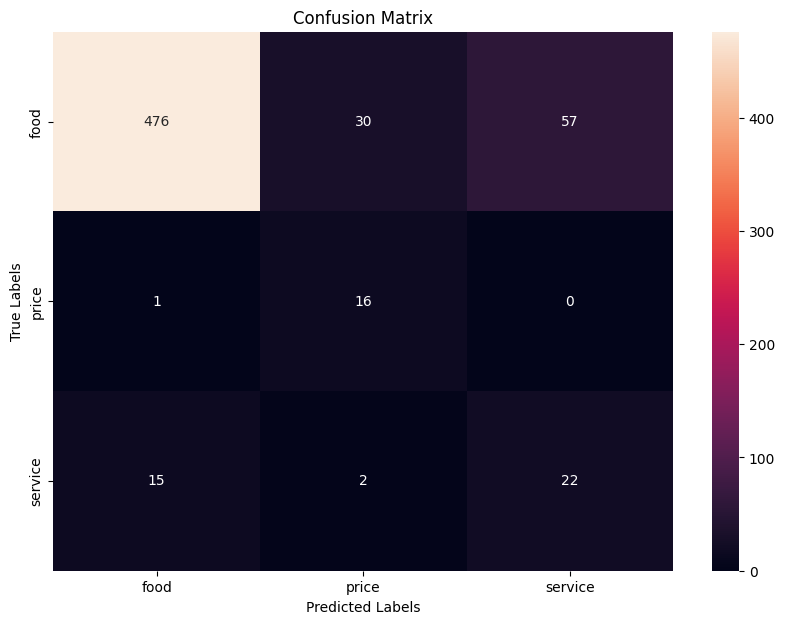

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Predicted Label: food


In [ ]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Bidirectional
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd
import random
import os
from google.colab import drive
from sklearn.preprocessing import LabelEncoder
from sklearn.utils import class_weight
from sklearn.metrics import accuracy_score
from tensorflow.keras.callbacks import EarlyStopping


# Mount Google Drive
drive.mount('/content/drive')

# Set seed for reproducibility
seed_value = 42
np.random.seed(seed_value)
random.seed(seed_value)
tf.random.set_seed(seed_value)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Load the dataset
data_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
df = pd.read_excel(data_path)

X = df['Comment']
y = df['Aspect']

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into 80% training, 10% validation, and 10% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=seed_value)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=seed_value)

# Tokenization and Padding
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len)

# Calculate class weights for class imbalance
class_weights = class_weight.compute_class_weight(
    'balanced', classes=np.unique(y_train), y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))

# Model parameters
embedding_dim = 256
num_classes = len(label_encoder.classes_)

# BiLSTM Model
input_layer = Input(shape=(max_len,))
embedding_layer = Embedding(max_words, embedding_dim)(input_layer)
bilstm_layer = Bidirectional(LSTM(64, return_sequences=False))(embedding_layer)
output_layer = Dense(num_classes, activation='softmax')(bilstm_layer)

model = Model(inputs=input_layer, outputs=output_layer)

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the model with validation, class weights, and early stopping
history = model.fit(
    X_train_pad, y_train,
    epochs=5,
    batch_size=16,
    validation_data=(X_val_pad, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

# Evaluate the model on the test set
results = model.evaluate(X_test_pad, y_test)
print(f'Test Loss: {results[0]}, Test Accuracy: {results[1]}')

y_pred = model.predict(X_test_pad).argmax(axis=1)

# Classification accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Classification Accuracy: {accuracy:.4f}')

# Classification report
report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)
print("Classification Report:")
print(report)

# Confusion Matrix with Seaborn Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Function to predict new comments
def predict_new_comment(new_comment, model, tokenizer, label_encoder, max_len=100):
    # Step 1: Preprocess the new comment (demojize, tokenize, and pad)
    new_comment_demojized = demojize_text(new_comment)  # Convert emojis to text
    new_comment_seq = tokenizer.texts_to_sequences([new_comment_demojized])  # Tokenize
    new_comment_pad = pad_sequences(new_comment_seq, maxlen=max_len)  # Pad sequence

    # Step 2: Predict using the trained model
    prediction = model.predict(new_comment_pad).argmax(axis=1)  # Prediction
    predicted_label = label_encoder.inverse_transform(prediction)  # Convert back to original label

    # Step 3: Return the prediction
    return predicted_label[0]

# Example usage:
new_comment = "খুবই ভালো ছিল"
predicted_label = predict_new_comment(new_comment, model, tokenizer, label_encoder)
print(f"Predicted Label: {predicted_label}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 65s 195ms/step - accuracy: 0.4994 - loss: 1.2141 - val_accuracy: 0.8611 - val_loss: 0.4858
Epoch 2/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 77s 180ms/step - accuracy: 0.8960 - loss: 0.4364 - val_accuracy: 0.8740 - val_loss: 0.4248
Epoch 3/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 53s 171ms/step - accuracy: 0.9386 - loss: 0.2117 - val_accuracy: 0.8724 - val_loss: 0.4400
Epoch 4/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 84s 179ms/step - accuracy: 0.9570 - loss: 0.1339 - val_accuracy: 0.8772 - val_loss: 0.4490
Epoch 5/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 55s 177ms/step - accuracy: 0.9690 - loss: 0.0977 - val_accuracy: 0.8805 - val_loss: 0.4447
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.8908 - loss: 0.4194
Test Loss: 0.42825406789779663, Test Accuracy: 0.8756058216094971
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step
Classification Accuracy: 0.8756
Classific

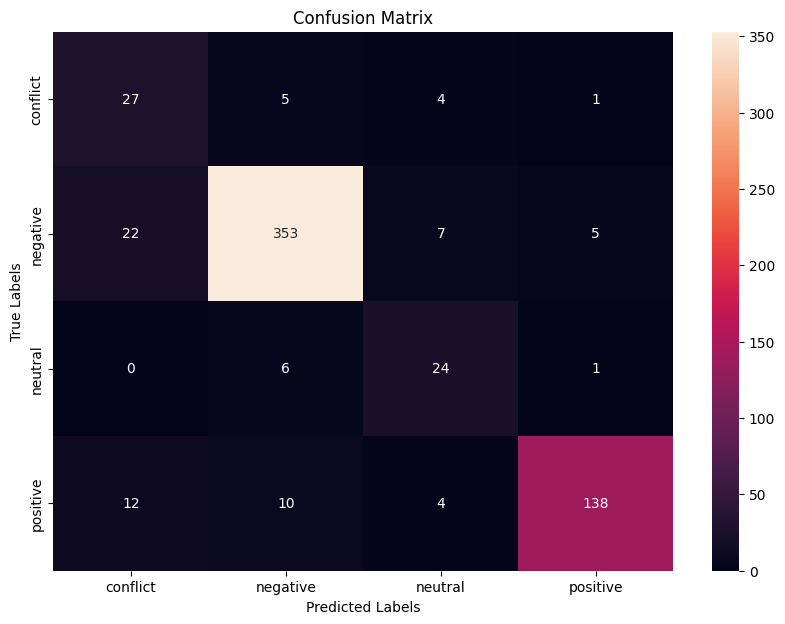

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Predicted Label: positive


In [ ]:
!pip install emoji
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Bidirectional
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import emoji
import pandas as pd
import random
import os
from google.colab import drive
from sklearn.preprocessing import LabelEncoder
from sklearn.utils import class_weight
from sklearn.metrics import accuracy_score
from tensorflow.keras.callbacks import EarlyStopping


# Mount Google Drive
drive.mount('/content/drive')

# Set seed for reproducibility
seed_value = 42
np.random.seed(seed_value)
random.seed(seed_value)
tf.random.set_seed(seed_value)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Load the dataset
data_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
df = pd.read_excel(data_path)

# Emoji processing function
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
df['Comment'] = df['Comment'].apply(demojize_text)

# Define X and y for classification, you can switch between Sentiment and Aspect by changing 'y'
X = df['Comment']
y = df['Sentiment']  # Change to df['Aspect'] for Aspect classification

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into 80% training, 10% validation, and 10% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=seed_value)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=seed_value)

# Tokenization and Padding
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len)

# Calculate class weights for class imbalance
class_weights = class_weight.compute_class_weight(
    'balanced', classes=np.unique(y_train), y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))

# Model parameters
embedding_dim = 256
num_classes = len(label_encoder.classes_)

# BiLSTM Model
input_layer = Input(shape=(max_len,))
embedding_layer = Embedding(max_words, embedding_dim)(input_layer)
bilstm_layer = Bidirectional(LSTM(64, return_sequences=False))(embedding_layer)
output_layer = Dense(num_classes, activation='softmax')(bilstm_layer)

model = Model(inputs=input_layer, outputs=output_layer)

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the model with validation, class weights, and early stopping
history = model.fit(
    X_train_pad, y_train,
    epochs=5,
    batch_size=16,
    validation_data=(X_val_pad, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

# Evaluate the model on the test set
results = model.evaluate(X_test_pad, y_test)
print(f'Test Loss: {results[0]}, Test Accuracy: {results[1]}')

y_pred = model.predict(X_test_pad).argmax(axis=1)

# Classification accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Classification Accuracy: {accuracy:.4f}')

# Classification report
report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)
print("Classification Report:")
print(report)

# Confusion Matrix with Seaborn Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Function to predict new comments
def predict_new_comment(new_comment, model, tokenizer, label_encoder, max_len=100):
    # Step 1: Preprocess the new comment (demojize, tokenize, and pad)
    new_comment_demojized = demojize_text(new_comment)  # Convert emojis to text
    new_comment_seq = tokenizer.texts_to_sequences([new_comment_demojized])  # Tokenize
    new_comment_pad = pad_sequences(new_comment_seq, maxlen=max_len)  # Pad sequence

    # Step 2: Predict using the trained model
    prediction = model.predict(new_comment_pad).argmax(axis=1)  # Prediction
    predicted_label = label_encoder.inverse_transform(prediction)  # Convert back to original label

    # Step 3: Return the prediction
    return predicted_label[0]

# Example usage:
new_comment = "খুবই ভালো ছিল"
predicted_label = predict_new_comment(new_comment, model, tokenizer, label_encoder)
print(f"Predicted Label: {predicted_label}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 87s 236ms/step - accuracy: 0.4932 - loss: 1.2075 - val_accuracy: 0.8659 - val_loss: 0.4788
Epoch 2/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 62s 173ms/step - accuracy: 0.8909 - loss: 0.4231 - val_accuracy: 0.8659 - val_loss: 0.4433
Epoch 3/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 81s 172ms/step - accuracy: 0.9380 - loss: 0.2182 - val_accuracy: 0.8708 - val_loss: 0.4375
Epoch 4/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 83s 175ms/step - accuracy: 0.9566 - loss: 0.1372 - val_accuracy: 0.8756 - val_loss: 0.4319
Epoch 5/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 56s 180ms/step - accuracy: 0.9639 - loss: 0.1053 - val_accuracy: 0.8708 - val_loss: 0.4804
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.8796 - loss: 0.4793
Test Loss: 0.4903707802295685, Test Accuracy: 0.8659127354621887
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 136ms/step
Classification Accuracy: 0.8659
Classific

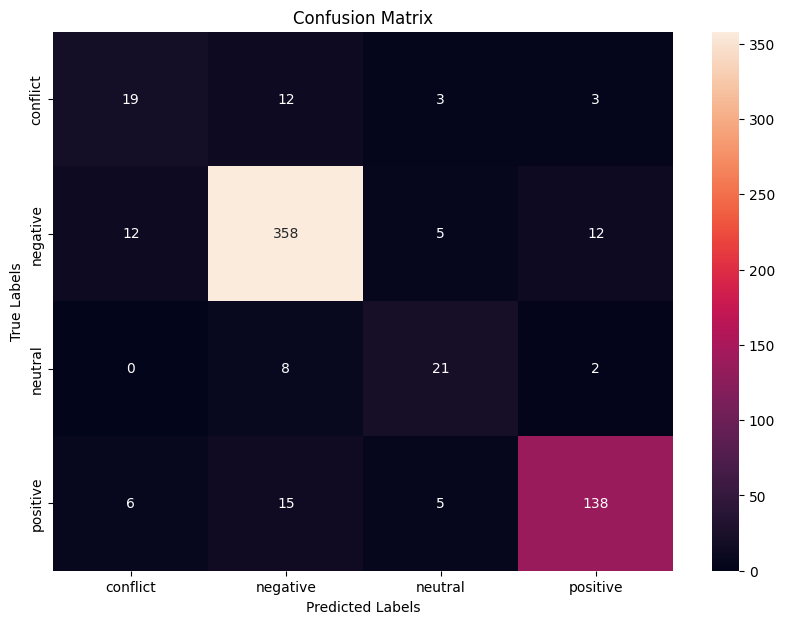

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
Predicted Label: positive


In [ ]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Bidirectional
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd
import random
import os
from google.colab import drive
from sklearn.preprocessing import LabelEncoder
from sklearn.utils import class_weight
from sklearn.metrics import accuracy_score
from tensorflow.keras.callbacks import EarlyStopping


# Mount Google Drive
drive.mount('/content/drive')

# Set seed for reproducibility
seed_value = 42
np.random.seed(seed_value)
random.seed(seed_value)
tf.random.set_seed(seed_value)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Load the dataset
data_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
df = pd.read_excel(data_path)

# Define X and y for classification, you can switch between Sentiment and Aspect by changing 'y'
X = df['Comment']
y = df['Sentiment']

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into 80% training, 10% validation, and 10% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=seed_value)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=seed_value)

# Tokenization and Padding
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len)

# Calculate class weights for class imbalance
class_weights = class_weight.compute_class_weight(
    'balanced', classes=np.unique(y_train), y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))

# Model parameters
embedding_dim = 256
num_classes = len(label_encoder.classes_)

# BiLSTM Model
input_layer = Input(shape=(max_len,))
embedding_layer = Embedding(max_words, embedding_dim)(input_layer)
bilstm_layer = Bidirectional(LSTM(64, return_sequences=False))(embedding_layer)
output_layer = Dense(num_classes, activation='softmax')(bilstm_layer)

model = Model(inputs=input_layer, outputs=output_layer)

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the model with validation, class weights, and early stopping
history = model.fit(
    X_train_pad, y_train,
    epochs=5,
    batch_size=16,
    validation_data=(X_val_pad, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

# Evaluate the model on the test set
results = model.evaluate(X_test_pad, y_test)
print(f'Test Loss: {results[0]}, Test Accuracy: {results[1]}')

y_pred = model.predict(X_test_pad).argmax(axis=1)

# Classification accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Classification Accuracy: {accuracy:.4f}')

# Classification report
report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)
print("Classification Report:")
print(report)

# Confusion Matrix with Seaborn Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Function to predict new comments
def predict_new_comment(new_comment, model, tokenizer, label_encoder, max_len=100):
    # Step 1: Preprocess the new comment (demojize, tokenize, and pad)
    new_comment_demojized = demojize_text(new_comment)  # Convert emojis to text
    new_comment_seq = tokenizer.texts_to_sequences([new_comment_demojized])  # Tokenize
    new_comment_pad = pad_sequences(new_comment_seq, maxlen=max_len)  # Pad sequence

    # Step 2: Predict using the trained model
    prediction = model.predict(new_comment_pad).argmax(axis=1)  # Prediction
    predicted_label = label_encoder.inverse_transform(prediction)  # Convert back to original label

    # Step 3: Return the prediction
    return predicted_label[0]

# Example usage:
new_comment = "খুবই ভালো ছিল"
predicted_label = predict_new_comment(new_comment, model, tokenizer, label_encoder)
print(f"Predicted Label: {predicted_label}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 26s 78ms/step - accuracy: 0.6110 - loss: 0.9702 - val_accuracy: 0.7964 - val_loss: 0.8759
Epoch 2/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 41s 79ms/step - accuracy: 0.8428 - loss: 0.4492 - val_accuracy: 0.8191 - val_loss: 0.7490
Epoch 3/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 40s 76ms/step - accuracy: 0.8896 - loss: 0.2875 - val_accuracy: 0.8546 - val_loss: 0.5890
Epoch 4/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 42s 79ms/step - accuracy: 0.9132 - loss: 0.2338 - val_accuracy: 0.8498 - val_loss: 0.6826
Epoch 5/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 42s 83ms/step - accuracy: 0.9203 - loss: 0.2594 - val_accuracy: 0.8546 - val_loss: 0.6681
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8555 - loss: 0.5589
Test Loss: 0.5638813972473145, Test Accuracy: 0.8529887199401855
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
Classification Accuracy: 0.8530
Classification 

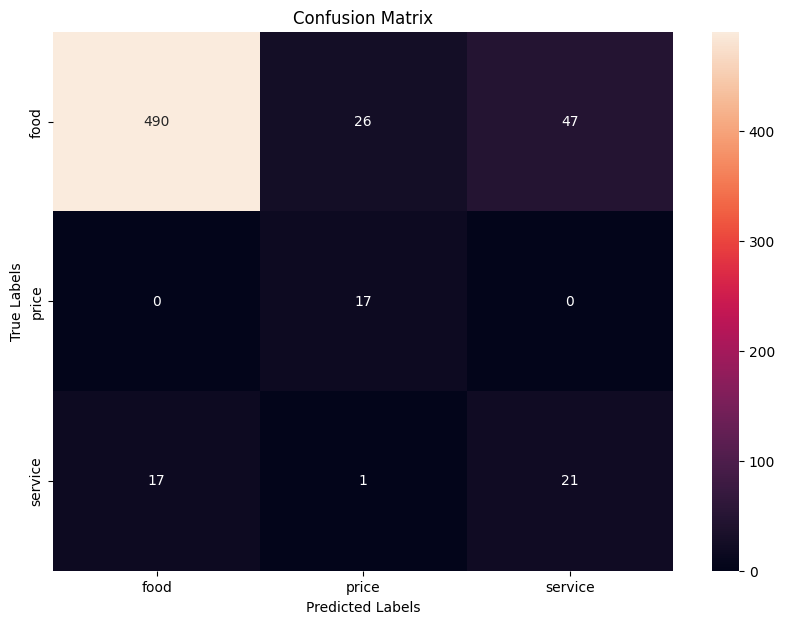

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
Predicted Label: food


In [ ]:
!pip install emoji
from sklearn.utils import class_weight
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd
import random
import emoji
import os
from google.colab import drive
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from tensorflow.keras.callbacks import EarlyStopping

# Mount Google Drive
drive.mount('/content/drive')

# Set seed for reproducibility
seed_value = 42
np.random.seed(seed_value)
random.seed(seed_value)
tf.random.set_seed(seed_value)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Load the dataset
data_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
df = pd.read_excel(data_path)

# Emoji processing function
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
df['Comment'] = df['Comment'].apply(demojize_text)

# Define X and y for classification (Change 'Sentiment' to 'Aspect' if needed)
X = df['Comment']
y = df['Aspect']  # Change to df['Aspect'] for Aspect classification

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into 80% training, 10% validation, and 10% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=seed_value)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=seed_value)

# Tokenization and Padding
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len)

# Calculate class weights for class imbalance
class_weights = class_weight.compute_class_weight(
    'balanced', classes=np.unique(y_train), y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))

# Model parameters
embedding_dim = 256
num_classes = len(label_encoder.classes_)

# CNN Model
input_layer = Input(shape=(max_len,))
embedding_layer = Embedding(max_words, embedding_dim)(input_layer)
conv_layer = Conv1D(filters=128, kernel_size=5, activation='relu')(embedding_layer)
pool_layer = GlobalMaxPooling1D()(conv_layer)
dropout_layer = Dropout(0.5)(pool_layer)
output_layer = Dense(num_classes, activation='softmax')(dropout_layer)

model = Model(inputs=input_layer, outputs=output_layer)

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the model with validation, class weights, and early stopping
history = model.fit(
    X_train_pad, y_train,
    epochs=5,
    batch_size=16,
    validation_data=(X_val_pad, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

# Evaluate the model on the test set
results = model.evaluate(X_test_pad, y_test)
print(f'Test Loss: {results[0]}, Test Accuracy: {results[1]}')

y_pred = model.predict(X_test_pad).argmax(axis=1)

# Classification accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Classification Accuracy: {accuracy:.4f}')

# Classification report
report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)
print("Classification Report:")
print(report)

# Confusion Matrix with Seaborn Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Function to predict new comments
def predict_new_comment(new_comment, model, tokenizer, label_encoder, max_len=100):
    # Step 1: Preprocess the new comment (demojize, tokenize, and pad)
    new_comment_demojized = demojize_text(new_comment)  # Convert emojis to text
    new_comment_seq = tokenizer.texts_to_sequences([new_comment_demojized])  # Tokenize
    new_comment_pad = pad_sequences(new_comment_seq, maxlen=max_len)  # Pad sequence

    # Step 2: Predict using the trained model
    prediction = model.predict(new_comment_pad).argmax(axis=1)  # Prediction
    predicted_label = label_encoder.inverse_transform(prediction)  # Convert back to original label

    # Step 3: Return the prediction
    return predicted_label[0]

# Example usage:
new_comment = "খুবই ভালো ছিল"
predicted_label = predict_new_comment(new_comment, model, tokenizer, label_encoder)
print(f"Predicted Label: {predicted_label}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 30s 90ms/step - accuracy: 0.6036 - loss: 0.9700 - val_accuracy: 0.8029 - val_loss: 0.8677
Epoch 2/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 36s 75ms/step - accuracy: 0.8491 - loss: 0.4399 - val_accuracy: 0.8255 - val_loss: 0.7071
Epoch 3/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 43s 81ms/step - accuracy: 0.8901 - loss: 0.2816 - val_accuracy: 0.8449 - val_loss: 0.6116
Epoch 4/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 23s 75ms/step - accuracy: 0.9124 - loss: 0.2363 - val_accuracy: 0.8449 - val_loss: 0.6665
Epoch 5/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 41s 76ms/step - accuracy: 0.9153 - loss: 0.2692 - val_accuracy: 0.8481 - val_loss: 0.6968
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8598 - loss: 0.5839
Test Loss: 0.5825318694114685, Test Accuracy: 0.8529887199401855
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step
Classification Accuracy: 0.8530
Classification 

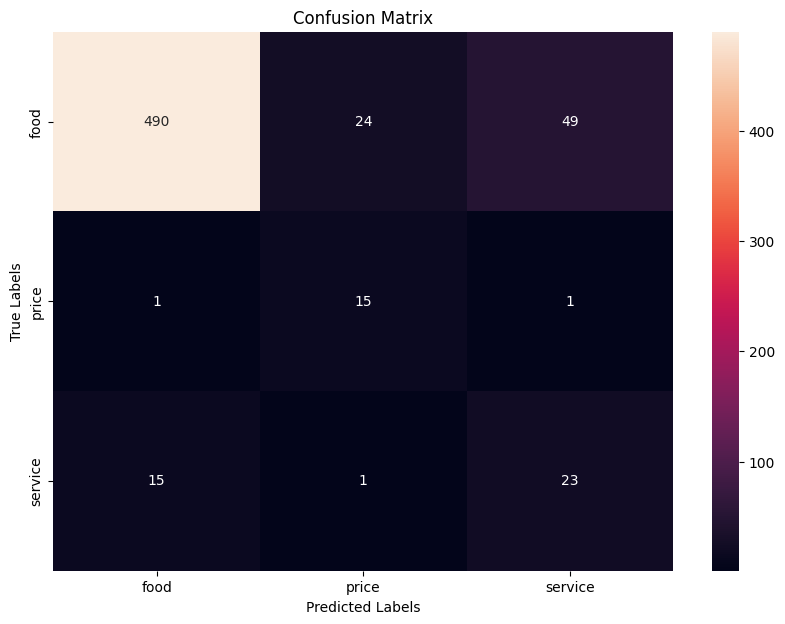

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Predicted Label: food


In [ ]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd
import random
import os
from google.colab import drive
from sklearn.preprocessing import LabelEncoder
from sklearn.utils import class_weight
from sklearn.metrics import accuracy_score
from tensorflow.keras.callbacks import EarlyStopping
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Mount Google Drive
drive.mount('/content/drive')

# Set seed for reproducibility
seed_value = 42
np.random.seed(seed_value)
random.seed(seed_value)
tf.random.set_seed(seed_value)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Load the dataset
data_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
df = pd.read_excel(data_path)


# Define X and y for classification (Change 'Sentiment' to 'Aspect' if needed)
X = df['Comment']
y = df['Aspect']  # Change to df['Aspect'] for Aspect classification

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into 80% training, 10% validation, and 10% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=seed_value)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=seed_value)

# Tokenization and Padding
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len)

# Calculate class weights for class imbalance
class_weights = class_weight.compute_class_weight(
    'balanced', classes=np.unique(y_train), y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))

# Model parameters
embedding_dim = 256
num_classes = len(label_encoder.classes_)

# CNN Model
input_layer = Input(shape=(max_len,))
embedding_layer = Embedding(max_words, embedding_dim)(input_layer)
conv_layer = Conv1D(filters=128, kernel_size=5, activation='relu')(embedding_layer)
pool_layer = GlobalMaxPooling1D()(conv_layer)
dropout_layer = Dropout(0.5)(pool_layer)
output_layer = Dense(num_classes, activation='softmax')(dropout_layer)

model = Model(inputs=input_layer, outputs=output_layer)

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the model with validation, class weights, and early stopping
history = model.fit(
    X_train_pad, y_train,
    epochs=5,
    batch_size=16,
    validation_data=(X_val_pad, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

# Evaluate the model on the test set
results = model.evaluate(X_test_pad, y_test)
print(f'Test Loss: {results[0]}, Test Accuracy: {results[1]}')

y_pred = model.predict(X_test_pad).argmax(axis=1)

# Classification accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Classification Accuracy: {accuracy:.4f}')

# Classification report
report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)
print("Classification Report:")
print(report)

# Confusion Matrix with Seaborn Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Function to predict new comments
def predict_new_comment(new_comment, model, tokenizer, label_encoder, max_len=100):
    # Step 1: Preprocess the new comment (demojize, tokenize, and pad)
    new_comment_demojized = demojize_text(new_comment)  # Convert emojis to text
    new_comment_seq = tokenizer.texts_to_sequences([new_comment_demojized])  # Tokenize
    new_comment_pad = pad_sequences(new_comment_seq, maxlen=max_len)  # Pad sequence

    # Step 2: Predict using the trained model
    prediction = model.predict(new_comment_pad).argmax(axis=1)  # Prediction
    predicted_label = label_encoder.inverse_transform(prediction)  # Convert back to original label

    # Step 3: Return the prediction
    return predicted_label[0]

# Example usage:
new_comment = "খুবই ভালো ছিল"
predicted_label = predict_new_comment(new_comment, model, tokenizer, label_encoder)
print(f"Predicted Label: {predicted_label}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 27s 81ms/step - accuracy: 0.5202 - loss: 1.2347 - val_accuracy: 0.8675 - val_loss: 0.4908
Epoch 2/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 40s 77ms/step - accuracy: 0.8682 - loss: 0.4879 - val_accuracy: 0.8934 - val_loss: 0.3810
Epoch 3/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 43s 83ms/step - accuracy: 0.9237 - loss: 0.2814 - val_accuracy: 0.9047 - val_loss: 0.3880
Epoch 4/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 41s 83ms/step - accuracy: 0.9461 - loss: 0.1847 - val_accuracy: 0.8869 - val_loss: 0.4010
Epoch 5/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 39s 76ms/step - accuracy: 0.9597 - loss: 0.1433 - val_accuracy: 0.8885 - val_loss: 0.4885
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.8906 - loss: 0.4577
Test Loss: 0.4198361337184906, Test Accuracy: 0.8901454210281372
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step
Classification Accuracy: 0.8901
Classification 

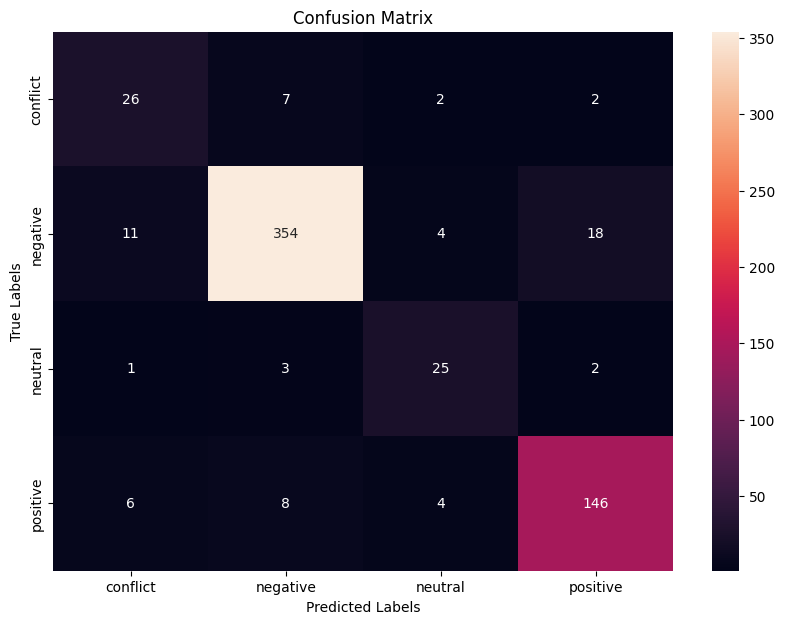

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
Predicted Label: positive


In [ ]:
!pip install emoji
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import emoji
import pandas as pd
import random
import os
from google.colab import drive
from sklearn.preprocessing import LabelEncoder
from sklearn.utils import class_weight
from sklearn.metrics import accuracy_score
from tensorflow.keras.callbacks import EarlyStopping

# Mount Google Drive
drive.mount('/content/drive')

# Set seed for reproducibility
seed_value = 42
np.random.seed(seed_value)
random.seed(seed_value)
tf.random.set_seed(seed_value)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Load the dataset
data_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
df = pd.read_excel(data_path)

# Emoji processing function
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
df['Comment'] = df['Comment'].apply(demojize_text)

# Define X and y for classification (Change 'Sentiment' to 'Aspect' if needed)
X = df['Comment']
y = df['Sentiment']  # Change to df['Aspect'] for Aspect classification

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into 80% training, 10% validation, and 10% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=seed_value)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=seed_value)

# Tokenization and Padding
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len)

# Calculate class weights for class imbalance
class_weights = class_weight.compute_class_weight(
    'balanced', classes=np.unique(y_train), y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))

# Model parameters
embedding_dim = 256
num_classes = len(label_encoder.classes_)

# CNN Model
input_layer = Input(shape=(max_len,))
embedding_layer = Embedding(max_words, embedding_dim)(input_layer)
conv_layer = Conv1D(filters=128, kernel_size=5, activation='relu')(embedding_layer)
pool_layer = GlobalMaxPooling1D()(conv_layer)
dropout_layer = Dropout(0.5)(pool_layer)
output_layer = Dense(num_classes, activation='softmax')(dropout_layer)

model = Model(inputs=input_layer, outputs=output_layer)

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the model with validation, class weights, and early stopping
history = model.fit(
    X_train_pad, y_train,
    epochs=5,
    batch_size=16,
    validation_data=(X_val_pad, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

# Evaluate the model on the test set
results = model.evaluate(X_test_pad, y_test)
print(f'Test Loss: {results[0]}, Test Accuracy: {results[1]}')

y_pred = model.predict(X_test_pad).argmax(axis=1)

# Classification accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Classification Accuracy: {accuracy:.4f}')

# Classification report
report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)
print("Classification Report:")
print(report)

# Confusion Matrix with Seaborn Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Function to predict new comments
def predict_new_comment(new_comment, model, tokenizer, label_encoder, max_len=100):
    # Step 1: Preprocess the new comment (demojize, tokenize, and pad)
    new_comment_demojized = demojize_text(new_comment)  # Convert emojis to text
    new_comment_seq = tokenizer.texts_to_sequences([new_comment_demojized])  # Tokenize
    new_comment_pad = pad_sequences(new_comment_seq, maxlen=max_len)  # Pad sequence

    # Step 2: Predict using the trained model
    prediction = model.predict(new_comment_pad).argmax(axis=1)  # Prediction
    predicted_label = label_encoder.inverse_transform(prediction)  # Convert back to original label

    # Step 3: Return the prediction
    return predicted_label[0]

# Example usage:
new_comment = "খুবই ভালো ছিল"
predicted_label = predict_new_comment(new_comment, model, tokenizer, label_encoder)
print(f"Predicted Label: {predicted_label}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 49s 145ms/step - accuracy: 0.5005 - loss: 1.2333 - val_accuracy: 0.8805 - val_loss: 0.4907
Epoch 2/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 33s 106ms/step - accuracy: 0.8686 - loss: 0.4969 - val_accuracy: 0.8982 - val_loss: 0.3584
Epoch 3/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 34s 85ms/step - accuracy: 0.9208 - loss: 0.2873 - val_accuracy: 0.8982 - val_loss: 0.3643
Epoch 4/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 23s 74ms/step - accuracy: 0.9486 - loss: 0.1824 - val_accuracy: 0.9047 - val_loss: 0.3869
Epoch 5/5
310/310 ━━━━━━━━━━━━━━━━━━━━ 41s 74ms/step - accuracy: 0.9578 - loss: 0.1574 - val_accuracy: 0.8982 - val_loss: 0.4454
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8862 - loss: 0.4382
Test Loss: 0.40623408555984497, Test Accuracy: 0.8901454210281372
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step
Classification Accuracy: 0.8901
Classificati

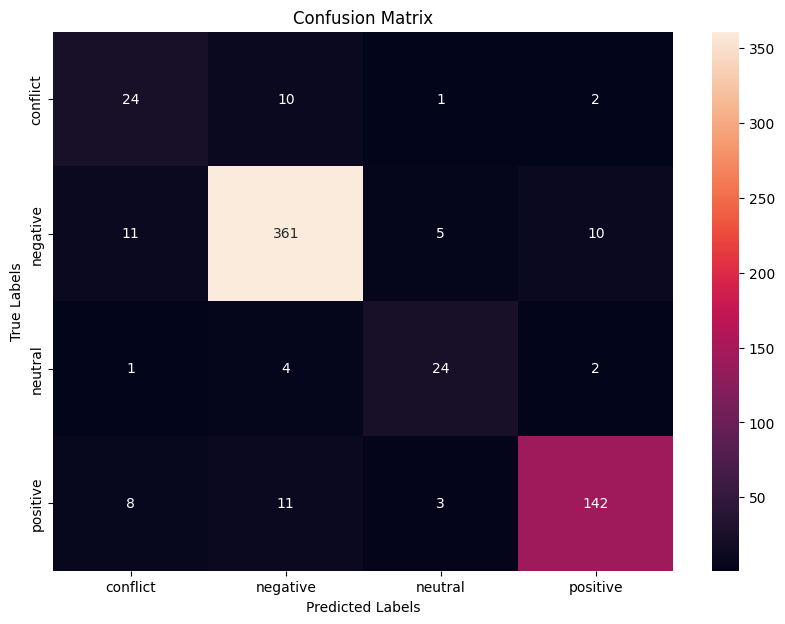

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
Predicted Label: positive


In [ ]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd
import random
import os
from google.colab import drive
from sklearn.preprocessing import LabelEncoder
from sklearn.utils import class_weight
from sklearn.metrics import accuracy_score
from tensorflow.keras.callbacks import EarlyStopping

# Mount Google Drive
drive.mount('/content/drive')

# Set seed for reproducibility
seed_value = 42
np.random.seed(seed_value)
random.seed(seed_value)
tf.random.set_seed(seed_value)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Load the dataset
data_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
df = pd.read_excel(data_path)

# Define X and y for classification (Change 'Sentiment' to 'Aspect' if needed)
X = df['Comment']
y = df['Sentiment']  # Change to df['Aspect'] for Aspect classification

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into 80% training, 10% validation, and 10% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=seed_value)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=seed_value)

# Tokenization and Padding
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len)

# Calculate class weights for class imbalance
class_weights = class_weight.compute_class_weight(
    'balanced', classes=np.unique(y_train), y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))

# Model parameters
embedding_dim = 256
num_classes = len(label_encoder.classes_)

# CNN Model
input_layer = Input(shape=(max_len,))
embedding_layer = Embedding(max_words, embedding_dim)(input_layer)
conv_layer = Conv1D(filters=128, kernel_size=5, activation='relu')(embedding_layer)
pool_layer = GlobalMaxPooling1D()(conv_layer)
dropout_layer = Dropout(0.5)(pool_layer)
output_layer = Dense(num_classes, activation='softmax')(dropout_layer)

model = Model(inputs=input_layer, outputs=output_layer)

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the model with validation, class weights, and early stopping
history = model.fit(
    X_train_pad, y_train,
    epochs=5,
    batch_size=16,
    validation_data=(X_val_pad, y_val),
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

# Evaluate the model on the test set
results = model.evaluate(X_test_pad, y_test)
print(f'Test Loss: {results[0]}, Test Accuracy: {results[1]}')

y_pred = model.predict(X_test_pad).argmax(axis=1)

# Classification accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Classification Accuracy: {accuracy:.4f}')

# Classification report
report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)
print("Classification Report:")
print(report)

# Confusion Matrix with Seaborn Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Function to predict new comments
def predict_new_comment(new_comment, model, tokenizer, label_encoder, max_len=100):
    # Step 1: Preprocess the new comment (demojize, tokenize, and pad)
    new_comment_demojized = demojize_text(new_comment)  # Convert emojis to text
    new_comment_seq = tokenizer.texts_to_sequences([new_comment_demojized])  # Tokenize
    new_comment_pad = pad_sequences(new_comment_seq, maxlen=max_len)  # Pad sequence

    # Step 2: Predict using the trained model
    prediction = model.predict(new_comment_pad).argmax(axis=1)  # Prediction
    predicted_label = label_encoder.inverse_transform(prediction)  # Convert back to original label

    # Step 3: Return the prediction
    return predicted_label[0]

# Example usage:
new_comment = "খুবই ভালো ছিল"
predicted_label = predict_new_comment(new_comment, model, tokenizer, label_encoder)
print(f"Predicted Label: {predicted_label}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (4952,)
Validation data shape: (619,)
Testing data shape: (619,)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-multilingual-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
100%|██████████| 39/39 [00:04<00:00,  7.89it/s]


Epoch 1, Train Loss: 0.5563, Val Loss: 0.3301


100%|██████████| 39/39 [00:04<00:00,  7.94it/s]


Epoch 2, Train Loss: 0.3156, Val Loss: 0.3019


...

Epoch 4, Train Loss: 0.1883, Val Loss: 0.2918


100%|██████████| 39/39 [00:04<00:00,  7.95it/s]
<ipython-input-2-c4b37621bb6b>:177: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_mode

Epoch 5, Train Loss: 0.1796, Val Loss: 0.3144


100%|██████████| 39/39 [00:09<00:00,  4.30it/s]


Classification Accuracy: 0.8885
Classification Report:
              precision    recall  f1-score   support

    conflict       0.60      0.68      0.63        37
    negative       0.93      0.94      0.93       387
     neutral       0.81      0.71      0.76        31
    positive       0.89      0.86      0.87       164

    accuracy                           0.89       619
   macro avg       0.81      0.80      0.80       619
weighted avg       0.89      0.89      0.89       619



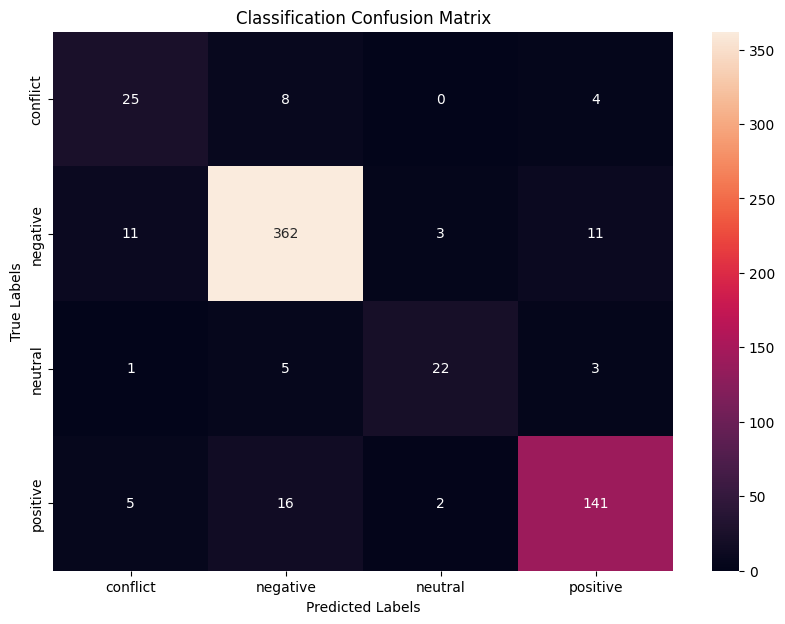

positive


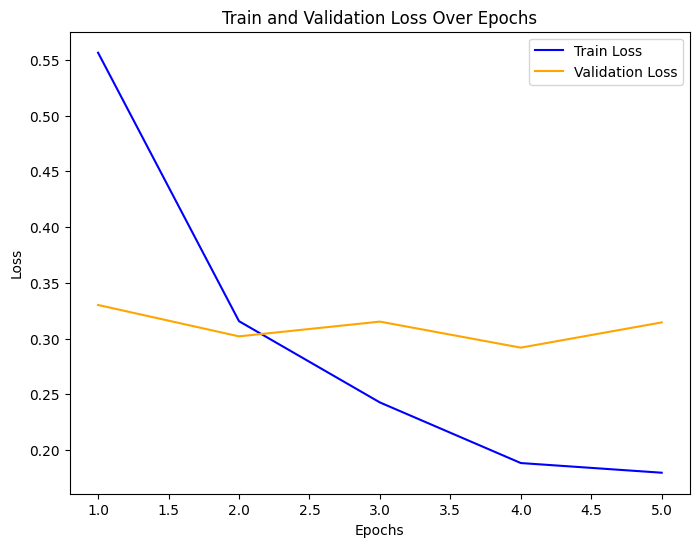

In [ ]:
# Install necessary packages
!pip install transformers
!pip install torch torchvision torchaudio
!pip install scikit-learn
!pip install pandas
!pip install openpyxl
!pip install emoji
!pip install seaborn

# Import Libraries
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from transformers import BertTokenizer, BertForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np
import random
import os
import emoji
import seaborn as sns

# Set random seed for reproducibility
seed_value = 42
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)
os.environ['PYTHONHASHSEED'] = str(seed_value)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Load Dataset from drive
file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(file_path)

def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

# Define X and y for classification (General approach)
X = data['Comment']
y = data['Sentiment']

# Encode the chosen target variable (Aspect or Sentiment)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into training and testing sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_val.shape)
print("Testing data shape:", X_test.shape)

# Prepare Input for BERT
tokenizer = BertTokenizer.from_pretrained('bert-base-multilingual-uncased')

def encode_data(comments):
    return tokenizer(comments.tolist(),
                     padding=True,
                     truncation=True,
                     return_tensors='pt',
                     max_length=256)

train_encodings = encode_data(X_train)
val_encodings = encode_data(X_val)
test_encodings = encode_data(X_test)

# Set device (GPU or CPU)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Create a Dataset Class
class ABSDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx]).to(device)  # Move labels to the device
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = ABSDataset(train_encodings, y_train)
val_dataset = ABSDataset(val_encodings, y_val)
test_dataset = ABSDataset(test_encodings, y_test)

model = BertForSequenceClassification.from_pretrained('bert-base-multilingual-uncased', num_labels=len(label_encoder.classes_))

# Move model to the device
model.to(device)

# Prepare DataLoader
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# Set optimizer and learning rate
weight_decay = 1e-5
optimizer = AdamW(model.parameters(), lr=3e-5, weight_decay=weight_decay)

train_losses = []
val_losses = []  # Define val_losses here to track validation losses

# Early stopping variables
patience = 2
best_val_loss = float('inf')
epochs_without_improvement = 0

# Training the model with validation and early stopping
for epoch in range(5):
    model.train()
    train_loss = 0
    for batch in tqdm(train_loader):
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        logits = model(input_ids, attention_mask=attention_mask).logits

        loss_fct = nn.CrossEntropyLoss()
        loss = loss_fct(logits, labels)

        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation step
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in tqdm(val_loader):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            logits = model(input_ids, attention_mask=attention_mask).logits
            loss = loss_fct(logits, labels)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(f"Epoch {epoch + 1}, Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}")

    # Early stopping check
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        epochs_without_improvement = 0
        # Save the best model weights
        torch.save(model.state_dict(), "best_model.pth")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping triggered!")
            break

# Load the best model for final evaluation
model.load_state_dict(torch.load("best_model.pth"))

# Evaluate the Model on the test set
model.eval()

preds = []

with torch.no_grad():
    for batch in tqdm(test_loader):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        logits = model(input_ids, attention_mask=attention_mask).logits
        preds.append(torch.argmax(logits, dim=1).cpu().numpy())

# Flatten the list
preds = [item for sublist in preds for item in sublist]

# Decode the predictions
decoded_preds = label_encoder.inverse_transform(preds)


# Calculate accuracy for classification
accuracy = accuracy_score(y_test, preds)

# Print the result
print(f'Classification Accuracy: {accuracy:.4f}')

# Generate classification report
report = classification_report(y_test, preds, target_names=label_encoder.classes_)

# Print the report
print("Classification Report:")
print(report)

# Generate confusion matrix
cm = confusion_matrix(y_test, preds)

# Plot the confusion matrix using Seaborn's heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Classification Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Function to predict sentiment or aspect for a new comment
def predict_comment(comment, model, tokenizer, label_encoder, device):
    # Preprocess the comment (demojize if needed)
    comment = demojize_text(comment)

    # Tokenize the comment
    encodings = tokenizer([comment], padding=True, truncation=True, return_tensors='pt', max_length=256)

    # Move tensors to the device
    input_ids = encodings['input_ids'].to(device)
    attention_mask = encodings['attention_mask'].to(device)

    # Make predictions
    model.eval()
    with torch.no_grad():
        logits = model(input_ids, attention_mask=attention_mask).logits
        predicted_class = torch.argmax(logits, dim=1).item()

    # Decode the predicted class label
    predicted_label = label_encoder.inverse_transform([predicted_class])

    return predicted_label[0]

# Example Usage: Predicting Sentiment or Aspect for a New Comment
new_comment_1 = "খুবই ভালো ছিল"
print(predict_comment(new_comment_1, model, tokenizer, label_encoder, device))

# Plotting the train and validation loss
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Train Loss', color='blue')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Train and Validation Loss Over Epochs')
plt.legend()
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (4952,)
Validation data shape: (619,)
Testing data shape: (619,)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-multilingual-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
100%|██████████| 39/39 [00:03<00:00, 10.98it/s]


Epoch 1, Train Loss: 0.5467, Val Loss: 0.3115


100%|██████████| 39/39 [00:03<00:00, 10.89it/s]


Epoch 2, Train Loss: 0.3185, Val Loss: 0.2774


...

Epoch 4, Train Loss: 0.1943, Val Loss: 0.2899


100%|██████████| 39/39 [00:03<00:00, 10.95it/s]
<ipython-input-3-687e9bb742f9>:169: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_mode

Epoch 5, Train Loss: 0.1724, Val Loss: 0.2924
Early stopping triggered!


100%|██████████| 39/39 [00:03<00:00, 11.31it/s]


Classification Accuracy: 0.8772
Classification Report:
              precision    recall  f1-score   support

    conflict       0.65      0.65      0.65        37
    negative       0.94      0.92      0.93       387
     neutral       0.76      0.61      0.68        31
    positive       0.81      0.88      0.85       164

    accuracy                           0.88       619
   macro avg       0.79      0.77      0.78       619
weighted avg       0.88      0.88      0.88       619



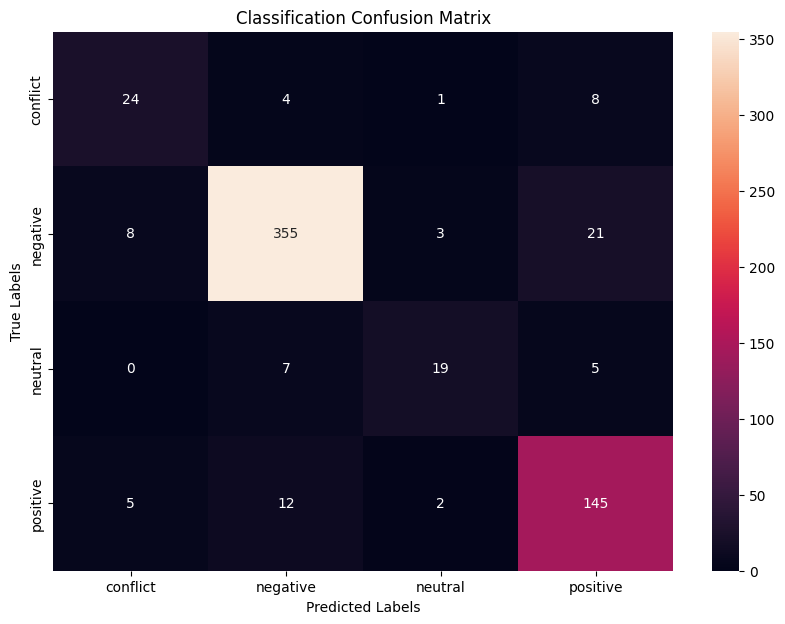

positive


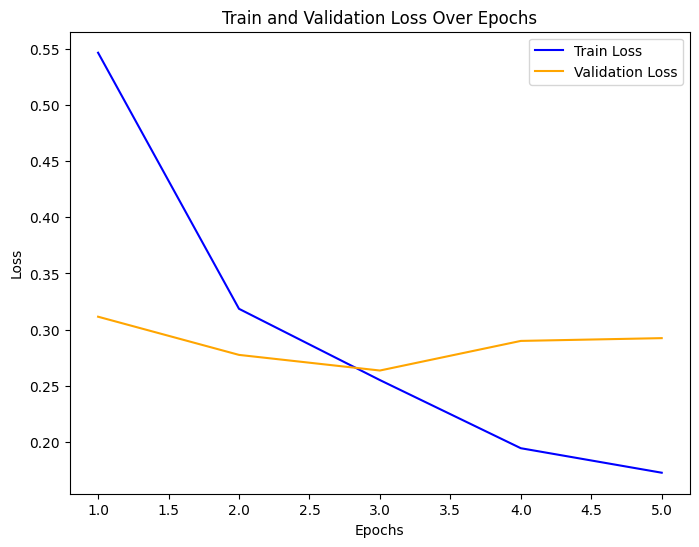

In [ ]:
# Install necessary packages
!pip install transformers
!pip install torch torchvision torchaudio
!pip install scikit-learn
!pip install pandas
!pip install openpyxl
!pip install seaborn

# Import Libraries
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from transformers import BertTokenizer, BertForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np
import random
import os
import seaborn as sns

# Set random seed for reproducibility
seed_value = 42
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)
os.environ['PYTHONHASHSEED'] = str(seed_value)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Load Dataset from drive
file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(file_path)

# Define X and y for classification (General approach)
X = data['Comment']
y = data['Sentiment']

# Encode the chosen target variable (Aspect or Sentiment)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into training and testing sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_val.shape)
print("Testing data shape:", X_test.shape)

# Prepare Input for BERT
tokenizer = BertTokenizer.from_pretrained('bert-base-multilingual-uncased')

def encode_data(comments):
    return tokenizer(comments.tolist(),
                     padding=True,
                     truncation=True,
                     return_tensors='pt',
                     max_length=256)

train_encodings = encode_data(X_train)
val_encodings = encode_data(X_val)
test_encodings = encode_data(X_test)

# Set device (GPU or CPU)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Create a Dataset Class
class ABSDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx]).to(device)  # Move labels to the device
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = ABSDataset(train_encodings, y_train)
val_dataset = ABSDataset(val_encodings, y_val)
test_dataset = ABSDataset(test_encodings, y_test)

model = BertForSequenceClassification.from_pretrained('bert-base-multilingual-uncased', num_labels=len(label_encoder.classes_))

# Move model to the device
model.to(device)

# Prepare DataLoader
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# Set optimizer and learning rate
weight_decay = 1e-5
optimizer = AdamW(model.parameters(), lr=3e-5, weight_decay=weight_decay)

train_losses = []
val_losses = []  # Define val_losses here to track validation losses

# Early stopping variables
patience = 2
best_val_loss = float('inf')
epochs_without_improvement = 0

# Training the model with validation and early stopping
for epoch in range(5):
    model.train()
    train_loss = 0
    for batch in tqdm(train_loader):
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        logits = model(input_ids, attention_mask=attention_mask).logits

        loss_fct = nn.CrossEntropyLoss()
        loss = loss_fct(logits, labels)

        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation step
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in tqdm(val_loader):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            logits = model(input_ids, attention_mask=attention_mask).logits
            loss = loss_fct(logits, labels)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(f"Epoch {epoch + 1}, Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}")

    # Early stopping check
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        epochs_without_improvement = 0
        # Save the best model weights
        torch.save(model.state_dict(), "best_model.pth")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping triggered!")
            break

# Load the best model for final evaluation
model.load_state_dict(torch.load("best_model.pth"))

# Evaluate the Model on the test set
model.eval()

preds = []

with torch.no_grad():
    for batch in tqdm(test_loader):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        logits = model(input_ids, attention_mask=attention_mask).logits
        preds.append(torch.argmax(logits, dim=1).cpu().numpy())

# Flatten the list
preds = [item for sublist in preds for item in sublist]

# Decode the predictions
decoded_preds = label_encoder.inverse_transform(preds)

# Calculate accuracy for classification
accuracy = accuracy_score(y_test, preds)

# Print the result
print(f'Classification Accuracy: {accuracy:.4f}')

# Generate classification report
report = classification_report(y_test, preds, target_names=label_encoder.classes_)

# Print the report
print("Classification Report:")
print(report)

# Generate confusion matrix
cm = confusion_matrix(y_test, preds)

# Plot the confusion matrix using Seaborn's heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Classification Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Function to predict sentiment or aspect for a new comment
def predict_comment(comment, model, tokenizer, label_encoder, device):

    # Tokenize the comment
    encodings = tokenizer([comment], padding=True, truncation=True, return_tensors='pt', max_length=256)

    # Move tensors to the device
    input_ids = encodings['input_ids'].to(device)
    attention_mask = encodings['attention_mask'].to(device)

    # Make predictions
    model.eval()
    with torch.no_grad():
        logits = model(input_ids, attention_mask=attention_mask).logits
        predicted_class = torch.argmax(logits, dim=1).item()

    # Decode the predicted class label
    predicted_label = label_encoder.inverse_transform([predicted_class])

    return predicted_label[0]

# Example Usage: Predicting Sentiment or Aspect for a New Comment
new_comment_1 = "খুবই ভালো ছিল"
print(predict_comment(new_comment_1, model, tokenizer, label_encoder, device))

# Plotting the train and validation loss
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Train Loss', color='blue')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Train and Validation Loss Over Epochs')
plt.legend()
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (4952,)
Validation data shape: (619,)
Testing data shape: (619,)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-multilingual-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
100%|██████████| 39/39 [00:04<00:00,  7.91it/s]


Epoch 1, Train Loss: 0.3663, Val Loss: 0.2406


100%|██████████| 39/39 [00:04<00:00,  7.94it/s]


Epoch 2, Train Loss: 0.2394, Val Loss: 0.2409


...

Epoch 4, Train Loss: 0.1983, Val Loss: 0.2665


100%|██████████| 39/39 [00:04<00:00,  7.97it/s]
<ipython-input-4-e8d47c78a6f7>:177: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_mode

Epoch 5, Train Loss: 0.1830, Val Loss: 0.2658
Early stopping triggered!


100%|██████████| 39/39 [00:09<00:00,  4.31it/s]


Classification Accuracy: 0.8885
Classification Report:
              precision    recall  f1-score   support

        food       0.95      0.93      0.94       563
       price       0.48      0.65      0.55        17
     service       0.34      0.36      0.35        39

    accuracy                           0.89       619
   macro avg       0.59      0.65      0.61       619
weighted avg       0.90      0.89      0.89       619



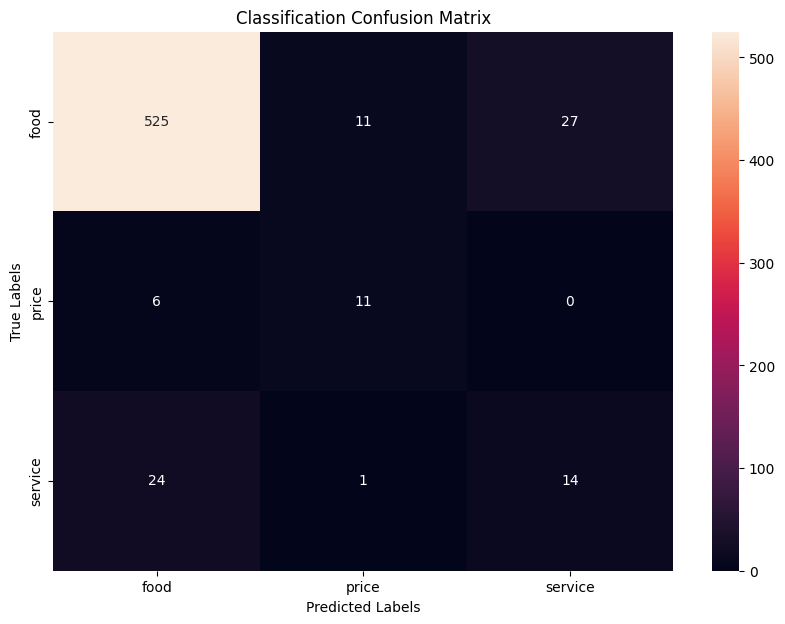

food


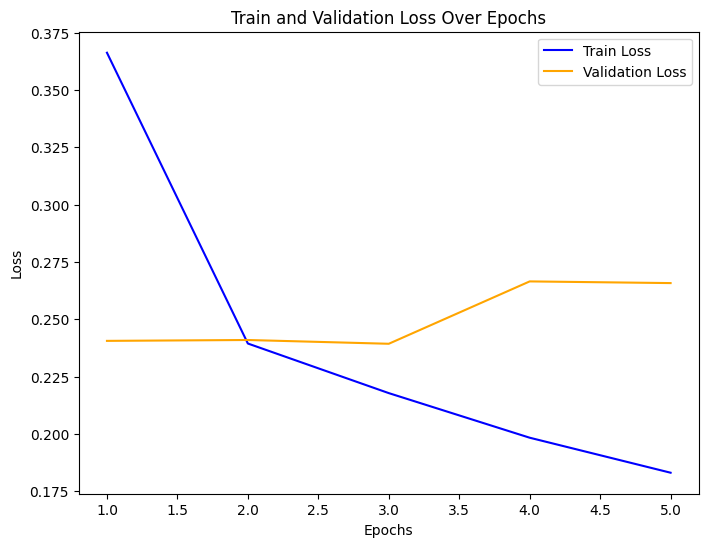

In [ ]:
# Install necessary packages
!pip install transformers
!pip install torch torchvision torchaudio
!pip install scikit-learn
!pip install pandas
!pip install openpyxl
!pip install emoji
!pip install seaborn

# Import Libraries
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from transformers import BertTokenizer, BertForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np
import random
import os
import emoji
import seaborn as sns

# Set random seed for reproducibility
seed_value = 42
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)
os.environ['PYTHONHASHSEED'] = str(seed_value)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Load Dataset from drive
file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(file_path)

def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

# Define X and y for classification (General approach)
X = data['Comment']
y = data['Aspect']

# Encode the chosen target variable (Aspect or Sentiment)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into training and testing sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_val.shape)
print("Testing data shape:", X_test.shape)

# Prepare Input for BERT
tokenizer = BertTokenizer.from_pretrained('bert-base-multilingual-uncased')

def encode_data(comments):
    return tokenizer(comments.tolist(),
                     padding=True,
                     truncation=True,
                     return_tensors='pt',
                     max_length=256)

train_encodings = encode_data(X_train)
val_encodings = encode_data(X_val)
test_encodings = encode_data(X_test)

# Set device (GPU or CPU)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Create a Dataset Class
class ABSDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx]).to(device)  # Move labels to the device
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = ABSDataset(train_encodings, y_train)
val_dataset = ABSDataset(val_encodings, y_val)
test_dataset = ABSDataset(test_encodings, y_test)

model = BertForSequenceClassification.from_pretrained('bert-base-multilingual-uncased', num_labels=len(label_encoder.classes_))

# Move model to the device
model.to(device)

# Prepare DataLoader
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# Set optimizer and learning rate
weight_decay = 1e-5
optimizer = AdamW(model.parameters(), lr=3e-5, weight_decay=weight_decay)

train_losses = []
val_losses = []  # Define val_losses here to track validation losses

# Early stopping variables
patience = 2
best_val_loss = float('inf')
epochs_without_improvement = 0

# Training the model with validation and early stopping
for epoch in range(5):
    model.train()
    train_loss = 0
    for batch in tqdm(train_loader):
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        logits = model(input_ids, attention_mask=attention_mask).logits

        loss_fct = nn.CrossEntropyLoss()
        loss = loss_fct(logits, labels)

        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation step
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in tqdm(val_loader):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            logits = model(input_ids, attention_mask=attention_mask).logits
            loss = loss_fct(logits, labels)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(f"Epoch {epoch + 1}, Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}")

    # Early stopping check
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        epochs_without_improvement = 0
        # Save the best model weights
        torch.save(model.state_dict(), "best_model.pth")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping triggered!")
            break

# Load the best model for final evaluation
model.load_state_dict(torch.load("best_model.pth"))

# Evaluate the Model on the test set
model.eval()

preds = []

with torch.no_grad():
    for batch in tqdm(test_loader):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        logits = model(input_ids, attention_mask=attention_mask).logits
        preds.append(torch.argmax(logits, dim=1).cpu().numpy())

# Flatten the list
preds = [item for sublist in preds for item in sublist]

# Decode the predictions
decoded_preds = label_encoder.inverse_transform(preds)


# Calculate accuracy for classification
accuracy = accuracy_score(y_test, preds)

# Print the result
print(f'Classification Accuracy: {accuracy:.4f}')

# Generate classification report
report = classification_report(y_test, preds, target_names=label_encoder.classes_)

# Print the report
print("Classification Report:")
print(report)

# Generate confusion matrix
cm = confusion_matrix(y_test, preds)

# Plot the confusion matrix using Seaborn's heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Classification Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Function to predict sentiment or aspect for a new comment
def predict_comment(comment, model, tokenizer, label_encoder, device):
    # Preprocess the comment (demojize if needed)
    comment = demojize_text(comment)

    # Tokenize the comment
    encodings = tokenizer([comment], padding=True, truncation=True, return_tensors='pt', max_length=256)

    # Move tensors to the device
    input_ids = encodings['input_ids'].to(device)
    attention_mask = encodings['attention_mask'].to(device)

    # Make predictions
    model.eval()
    with torch.no_grad():
        logits = model(input_ids, attention_mask=attention_mask).logits
        predicted_class = torch.argmax(logits, dim=1).item()

    # Decode the predicted class label
    predicted_label = label_encoder.inverse_transform([predicted_class])

    return predicted_label[0]

# Example Usage: Predicting Sentiment or Aspect for a New Comment
new_comment_1 = "খুবই ভালো ছিল"
print(predict_comment(new_comment_1, model, tokenizer, label_encoder, device))

# Plotting the train and validation loss
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Train Loss', color='blue')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Train and Validation Loss Over Epochs')
plt.legend()
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (4952,)
Validation data shape: (619,)
Testing data shape: (619,)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-multilingual-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
100%|██████████| 39/39 [00:03<00:00, 10.64it/s]


Epoch 1, Train Loss: 0.3747, Val Loss: 0.3251


100%|██████████| 39/39 [00:03<00:00, 10.82it/s]


Epoch 2, Train Loss: 0.2633, Val Loss: 0.2461


...

Epoch 4, Train Loss: 0.2020, Val Loss: 0.2321


100%|██████████| 39/39 [00:03<00:00, 10.94it/s]
<ipython-input-5-942410914075>:169: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_mode

Epoch 5, Train Loss: 0.1912, Val Loss: 0.2427
Early stopping triggered!


100%|██████████| 39/39 [00:03<00:00, 11.31it/s]


Classification Accuracy: 0.9015
Classification Report:
              precision    recall  f1-score   support

        food       0.95      0.94      0.95       563
       price       0.52      0.76      0.62        17
     service       0.40      0.36      0.38        39

    accuracy                           0.90       619
   macro avg       0.62      0.69      0.65       619
weighted avg       0.90      0.90      0.90       619



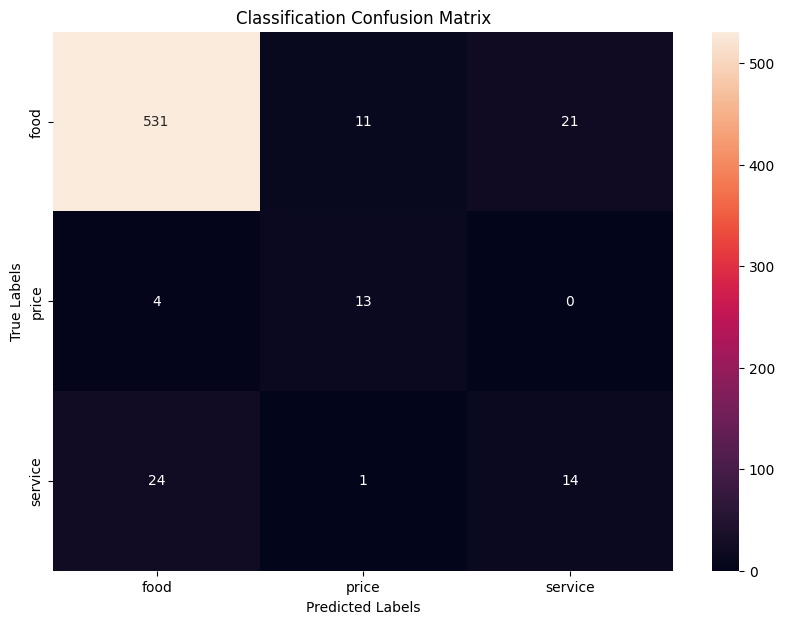

food


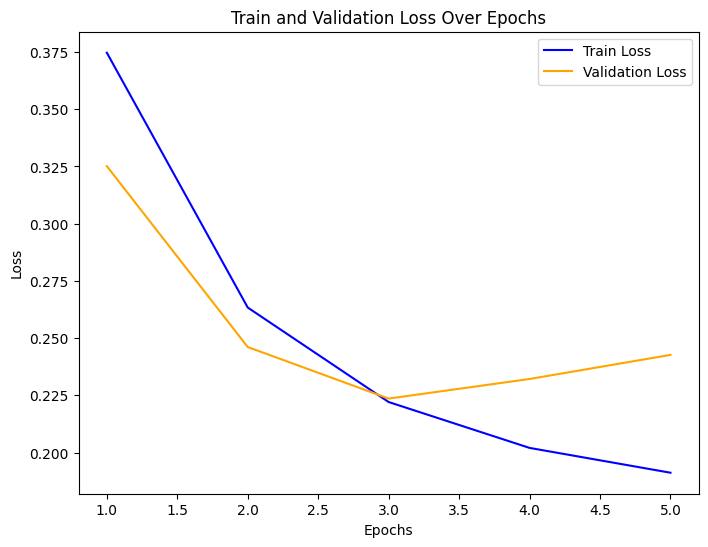

In [ ]:
# Install necessary packages
!pip install transformers
!pip install torch torchvision torchaudio
!pip install scikit-learn
!pip install pandas
!pip install openpyxl
!pip install seaborn

# Import Libraries
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from transformers import BertTokenizer, BertForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np
import random
import os
import seaborn as sns

# Set random seed for reproducibility
seed_value = 42
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)
os.environ['PYTHONHASHSEED'] = str(seed_value)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Load Dataset from drive
file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_Without_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(file_path)

# Define X and y for classification (General approach)
X = data['Comment']
y = data['Aspect']

# Encode the chosen target variable (Aspect or Sentiment)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into training and testing sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_val.shape)
print("Testing data shape:", X_test.shape)

# Prepare Input for BERT
tokenizer = BertTokenizer.from_pretrained('bert-base-multilingual-uncased')

def encode_data(comments):
    return tokenizer(comments.tolist(),
                     padding=True,
                     truncation=True,
                     return_tensors='pt',
                     max_length=256)

train_encodings = encode_data(X_train)
val_encodings = encode_data(X_val)
test_encodings = encode_data(X_test)

# Set device (GPU or CPU)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Create a Dataset Class
class ABSDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx]).to(device)  # Move labels to the device
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = ABSDataset(train_encodings, y_train)
val_dataset = ABSDataset(val_encodings, y_val)
test_dataset = ABSDataset(test_encodings, y_test)

model = BertForSequenceClassification.from_pretrained('bert-base-multilingual-uncased', num_labels=len(label_encoder.classes_))

# Move model to the device
model.to(device)

# Prepare DataLoader
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# Set optimizer and learning rate
weight_decay = 1e-5
optimizer = AdamW(model.parameters(), lr=3e-5, weight_decay=weight_decay)

train_losses = []
val_losses = []  # Define val_losses here to track validation losses

# Early stopping variables
patience = 2
best_val_loss = float('inf')
epochs_without_improvement = 0

# Training the model with validation and early stopping
for epoch in range(5):
    model.train()
    train_loss = 0
    for batch in tqdm(train_loader):
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        logits = model(input_ids, attention_mask=attention_mask).logits

        loss_fct = nn.CrossEntropyLoss()
        loss = loss_fct(logits, labels)

        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation step
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch in tqdm(val_loader):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            logits = model(input_ids, attention_mask=attention_mask).logits
            loss = loss_fct(logits, labels)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(f"Epoch {epoch + 1}, Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}")

    # Early stopping check
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        epochs_without_improvement = 0
        # Save the best model weights
        torch.save(model.state_dict(), "best_model.pth")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping triggered!")
            break

# Load the best model for final evaluation
model.load_state_dict(torch.load("best_model.pth"))

# Evaluate the Model on the test set
model.eval()

preds = []

with torch.no_grad():
    for batch in tqdm(test_loader):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        logits = model(input_ids, attention_mask=attention_mask).logits
        preds.append(torch.argmax(logits, dim=1).cpu().numpy())

# Flatten the list
preds = [item for sublist in preds for item in sublist]

# Decode the predictions
decoded_preds = label_encoder.inverse_transform(preds)

# Calculate accuracy for classification
accuracy = accuracy_score(y_test, preds)

# Print the result
print(f'Classification Accuracy: {accuracy:.4f}')

# Generate classification report
report = classification_report(y_test, preds, target_names=label_encoder.classes_)

# Print the report
print("Classification Report:")
print(report)

# Generate confusion matrix
cm = confusion_matrix(y_test, preds)

# Plot the confusion matrix using Seaborn's heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Classification Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Function to predict sentiment or aspect for a new comment
def predict_comment(comment, model, tokenizer, label_encoder, device):

    # Tokenize the comment
    encodings = tokenizer([comment], padding=True, truncation=True, return_tensors='pt', max_length=256)

    # Move tensors to the device
    input_ids = encodings['input_ids'].to(device)
    attention_mask = encodings['attention_mask'].to(device)

    # Make predictions
    model.eval()
    with torch.no_grad():
        logits = model(input_ids, attention_mask=attention_mask).logits
        predicted_class = torch.argmax(logits, dim=1).item()

    # Decode the predicted class label
    predicted_label = label_encoder.inverse_transform([predicted_class])

    return predicted_label[0]

# Example Usage: Predicting Sentiment or Aspect for a New Comment
new_comment_1 = "খুবই ভালো ছিল"
print(predict_comment(new_comment_1, model, tokenizer, label_encoder, device))

# Plotting the train and validation loss
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Train Loss', color='blue')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Train and Validation Loss Over Epochs')
plt.legend()
plt.show()

In [ ]:
import torch
from transformers import BertTokenizer, BertForSequenceClassification
from sklearn.preprocessing import LabelEncoder

def load_model_and_tokenizer():
    # Load the pre-trained tokenizer
    tokenizer = BertTokenizer.from_pretrained('bert-base-multilingual-uncased')

    # Load the trained model
    model = BertForSequenceClassification.from_pretrained('bert-base-multilingual-uncased', num_labels=5)  # Adjust num_labels
    model.load_state_dict(torch.load("best_model.pth"))
    model.eval()

    # Set device
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    model.to(device)

    return model, tokenizer, device

def predict_new_comment(comment, model, tokenizer, label_encoder, device):
    # Tokenize the comment
    encodings = tokenizer([comment], padding=True, truncation=True, return_tensors='pt', max_length=256)

    # Move tensors to the device
    input_ids = encodings['input_ids'].to(device)
    attention_mask = encodings['attention_mask'].to(device)

    # Make predictions
    with torch.no_grad():
        logits = model(input_ids, attention_mask=attention_mask).logits
        predicted_class = torch.argmax(logits, dim=1).item()

    # Decode the predicted class label
    predicted_label = label_encoder.inverse_transform([predicted_class])

    return predicted_label[0]

# Load model, tokenizer, and device
model, tokenizer, device = load_model_and_tokenizer()

# Load the label encoder (you may need to reload it if it's not already in memory)
label_encoder = LabelEncoder()
label_encoder.classes_ = ["class1", "class2", "class3", "class4", "class5"]  # Replace with actual class names

# Example Usage
print(predict_new_comment("খুবই ভালো ছিল", model, tokenizer, label_encoder, device))



ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "<ipython-input-4-7da74b170040>", line 2, in <cell line: 0>
    from transformers import BertTokenizer, BertForSequenceClassification
  File "<frozen importlib._bootstrap>", line 1229, in _handle_fromlist
  File "/usr/local/lib/python3.11/dist-packages/transformers/utils/import_utils.py", line 1806, in __getattr__
    value = getattr(module, name)
            ^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/transformers/utils/import_utils.py", line 1805, in __getattr__
    module = self._get_module(self._class_to_module[name])
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/transformers/utils/import_utils.py", line 1817, in _get_module
    return importlib.import_module("." + module_name, self.__name__)
     

In [ ]:
# Step 1: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Step 2: Install Required Libraries
!pip install pandas openpyxl

# Step 3: Load the Excel File
import pandas as pd

# Load the Excel file
file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
df = pd.read_excel(file_path)

# Step 4: Count Sentiments
sentiment_counts = df['Sentiment'].value_counts()
print("Sentiment Counts:")
print(sentiment_counts)

# Step 5: Count Aspects
aspect_counts = df['Aspect'].value_counts()
print("\nAspect Counts:")
print(aspect_counts)

# Step 6: (Optional) Combine Counts in a DataFrame
summary_counts = pd.DataFrame({
    'Sentiment': sentiment_counts,
    'Aspect': aspect_counts
}).fillna(0)  # Fill NaN values with 0 if they don't exist in one of the counts

print("\nSummary Counts:")
print(summary_counts)

Mounted at /content/drive
Sentiment Counts:
Sentiment
negative    3798
positive    1727
conflict     392
neutral      273
Name: count, dtype: int64

Aspect Counts:
Aspect
food       5555
service     424
price       211
Name: count, dtype: int64

Summary Counts:
          Sentiment  Aspect
conflict      392.0     0.0
food            0.0  5555.0
negative     3798.0     0.0
neutral       273.0     0.0
positive     1727.0     0.0
price           0.0   211.0
service         0.0   424.0


In [ ]:
# Step 1: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Step 2: Install Required Libraries
!pip install pandas openpyxl

# Step 3: Load the Excel File
import pandas as pd

# Load the Excel file
file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
df = pd.read_excel(file_path)

# Step 4: Normalize the data
df['Comment'] = df['Comment'].str.strip().str.lower()
df['Aspect'] = df['Aspect'].str.strip().str.lower()
df['Sentiment'] = df['Sentiment'].str.strip().str.lower()

# Step 5: Find Duplicate Rows
duplicates = df[df.duplicated(subset=['Comment', 'Aspect', 'Sentiment'], keep=False)]

# Get unique duplicates
unique_duplicates = duplicates.drop_duplicates(subset=['Comment', 'Aspect', 'Sentiment'])

# Count unique duplicates
count_unique_duplicates = unique_duplicates.shape[0]

# Display the unique duplicate rows and their count
print("Unique Duplicate Rows:")
print(unique_duplicates)
print("\nCount of Unique Duplicate Rows:", count_unique_duplicates)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Unique Duplicate Rows:
Empty DataFrame
Columns: [Comment, Aspect, Sentiment]
Index: []

Count of Unique Duplicate Rows: 0


In [ ]:
# Install necessary libraries
!pip install emoji
!pip install imbalanced-learn

# Import necessary libraries
from imblearn.over_sampling import SMOTE
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import pandas as pd
import emoji

# Load data from Google Drive Excel file (update the path if necessary)
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

# Separate features (X) and target labels (y)
X = data['Comment']
y = data['Sentiment']

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_int = label_encoder.fit_transform(y)

# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y_int, test_size=0.1, random_state=42)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

# Vectorize the text data using TfidfVectorizer
vectorizer = TfidfVectorizer()
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

# Apply SMOTE to the training data to handle class imbalance
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train_vectorized, y_train)

# Count the class distribution after SMOTE oversampling
y_resampled_counts = pd.Series(y_resampled).value_counts()

# Map back to original labels using label_encoder
y_resampled_labels = label_encoder.inverse_transform(y_resampled)
y_resampled_labels_counts = pd.Series(y_resampled_labels).value_counts()

# Print the class distribution after SMOTE oversampling
print("Class distribution after SMOTE oversampling:")
result = pd.DataFrame({
    'Aspect': y_resampled_labels_counts.index,
    'Count': y_resampled_labels_counts.values
})
print(result)


Training set size: 5571 samples
Test set size: 619 samples
Class distribution after SMOTE oversampling:
     Aspect  Count
0  negative   3401
1  positive   3401
2   neutral   3401
3  conflict   3401


In [ ]:
!pip install emoji
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

X = data['Comment']
y = data['Sentiment']

# Split data into training and testing sets with stratification to ensure balanced splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Convert string labels to integer labels
label_encoder = LabelEncoder()
y_train_int = label_encoder.fit_transform(y_train)
y_test_int = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)

# Display the encoded labels with their corresponding class names
for idx, label in enumerate(label_encoder.classes_):
    print(f'Encoded Label: {idx} -> Class: {label}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training data shape: (5571,)
Testing data shape: (619,)
Classes: ['conflict' 'negative' 'neutral' 'positive']
Encoded Label: 0 -> Class: conflict
Encoded Label: 1 -> Class: negative
Encoded Label: 2 -> Class: neutral
Encoded Label: 3 -> Class: positive


In [ ]:
!pip install emoji
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
import emoji
import seaborn as sns

# Mount Google Drive
drive.mount('/content/drive')

# Load data from Google Drive Excel file
data_file_path = '/content/drive/MyDrive/DATA/Bengali_Food_Reviews_With_Emoji_ABSA_By_Shihab-Mirza_Abir-Hossain_Suhala-Lamia.xlsx'
data = pd.read_excel(data_file_path)

# Define a function to demojize text
def demojize_text(text):
    return emoji.demojize(text)

# Process emojis in the comments for the entire dataset
data['Comment'] = data['Comment'].apply(demojize_text)

X = data['Comment']
y = data['Aspect']
def demojize_text_with_example(text):
    original_text = text
    transformed_text = emoji.demojize(text)
    return original_text, transformed_text

# Apply the function to the entire dataset and show the original vs. transformed data
example_transforms = data['Comment'].apply(demojize_text_with_example).head(10)  # Displaying the first 10 examples
example_transforms


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Comment
0,"(খাবারের মান আগের থেকে খারাপ হচ্ছে, খাবারের মা..."
1,"(খুবই ভালো ছিল, খুবই ভালো ছিল)"
2,(অসাধারণ :smiling_face_with_heart-eyes::smilin...
3,"(পরোটা অনেক শক্ত পরোটা আরো ভালো করতে হবে, পরোট..."
4,"(খাবারের মান খুবই ভালো ছিল, এবং ফ্রেশ ছিল, খাব..."
5,(বিফ খিচুড়ি অর্ডার করার ১ঘন্টা ৩০মিনিট পরে ৪পি...
6,"(রাইচের পরিমান কম অনেক আর তেল বেশি, রাইচের পরি..."
7,(খুবি বাজে ছিল খাবার পচা বাশি মাংস দিয়েছে তারা...
8,"(অর্ডার করলাম প্লেইন পোলাও , ডেলিভারি করলো খিচ..."
9,(তান্দুরি রুটি একেবারেই পাপড় ভাজার মতো শক্ত ছি...
